<a href="https://colab.research.google.com/github/yaroslavkarpenko701/E-commerce-Sales-Analysis/blob/main/ecommerce_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive/")

Mounted at /content/drive/


In [ ]:
from google.colab import auth
from google.cloud import bigquery

In [ ]:
%cd /content/drive/MyDrive/online_store_sales_analytics/

/content/drive/MyDrive/online_store_sales_analytics


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

import scipy.stats as scst

#1) Data overview

In [ ]:
auth.authenticate_user()

In [ ]:
client = bigquery.Client(project="data-analytics-mate")

In [ ]:
query = """
WITH session_combined AS(
SELECT
      s.date,
      s.ga_session_id,
      sp.continent,
      sp.country,
      sp.device,
      sp.browser,
      sp.mobile_model_name,
      sp.operating_system,
      sp.language,
      sp.name AS traffic_source_name,
      sp.channel

FROM `data-analytics-mate.DA.session` AS s
INNER JOIN `data-analytics-mate.DA.session_params` AS sp
  ON sp.ga_session_id = s.ga_session_id
),

account_session_combined AS(
SELECT
      session_combined.*,
      acs.account_id,
      acc.is_verified,
      acc.is_unsubscribed

FROM session_combined
LEFT JOIN `data-analytics-mate.DA.account_session` AS acs
  ON session_combined.ga_session_id = acs.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account` AS acc
  ON acc.id = acs.account_id
),

order_account_session_combined AS(
SELECT
      account_session_combined.*,
      ord.item_id,
      prd.category,
      prd.name AS product_name,
      prd.price,
      prd.short_description

FROM account_session_combined
LEFT JOIN `data-analytics-mate.DA.order` AS ord
  ON account_session_combined.ga_session_id = ord.ga_session_id
LEFT JOIN `data-analytics-mate.DA.product` AS prd
  ON ord.item_id = prd.item_id
)

SELECT *
FROM order_account_session_combined
"""

In [ ]:
query_job = client.query(query)  # Виконання SQL-запиту
results = query_job.result()  # Очікування завершення запиту

In [ ]:
df = results.to_dataframe(create_bqstorage_client = False)

In [ ]:
df.head()

,date,ga_session_id,continent,country,device,browser,mobile_model_name,operating_system,language,traffic_source_name,channel,account_id,is_verified,is_unsubscribed,item_id,category,product_name,price,short_description
0,2021-01-19,7268004754,(not set),(not set),desktop,Chrome,Chrome,Web,en-gb,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
1,2021-01-06,8321293308,(not set),(not set),desktop,Chrome,Chrome,Web,None,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
2,2020-11-05,4392362373,(not set),(not set),desktop,Chrome,Chrome,Web,None,(organic),Organic Search,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
3,2020-12-09,140108698,(not set),(not set),desktop,Chrome,Safari,Web,en-us,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
4,2020-11-10,8351127264,(not set),(not set),mobile,Safari,iPhone,Web,en-us,(organic),Organic Search,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   date                 349545 non-null  dbdate 
 1   ga_session_id        349545 non-null  Int64  
 2   continent            349545 non-null  object 
 3   country              349545 non-null  object 
 4   device               349545 non-null  object 
 5   browser              349545 non-null  object 
 6   mobile_model_name    349545 non-null  object 
 7   operating_system     349545 non-null  object 
 8   language             235279 non-null  object 
 9   traffic_source_name  349545 non-null  object 
 10  channel              349545 non-null  object 
 11  account_id           27945 non-null   Int64  
 12  is_verified          27945 non-null   Int64  
 13  is_unsubscribed      27945 non-null   Int64  
 14  item_id              33538 non-null   Int64  
 15  category         

В таблиці є 19 колонок, всі мають правильний тип даних, маємо 349545 рядків, з всіх стовпців можемо отримати таку інформацію як:
* дата сесії - ***date***
* ідентифікатор сесії - ***ga_session_id***
* Континент - ***continent***
* Країна - ***country***
* Девайс - ***device***
* Браузер - ***browser***
* назва моделі пристрою - ***mobile_model_name***
* операційна система - ***operating_system***
* мова браузера - ***language***
* інформація про джерело трафіку - ***traffic_source_name***
* канал трафіку - ***channel***
* ідентифікатор зареєстрованого користувача - ***account_id***
* чи підтвердив користувач свій email - ***is_verified***
* чи підписався користувач на розсилку - ***is_unsubscribed***
* ідентифікатор товару - ***item_id***
* категорія товару - ***category***
* назва товару - ***product_name***
* Ціна - ***price***
* короткий опис товару - ***short_description***


In [ ]:
df.describe()

,ga_session_id,account_id,is_verified,is_unsubscribed,item_id,price
count,349545.0,27945.0,27945.0,27945.0,33538.0,33538.000000
mean,4992250296.631739,659005.065557,0.71698,0.16944,47753715.295247,953.298679
std,2887450949.537772,13216.529465,0.450474,0.375147,28778685.186469,1317.001775
min,1205.0,636133.0,0.0,0.0,91415.0,3.000000
25%,2493646855.0,647576.0,0.0,0.0,20346072.0,170.000000
50%,4988476074.0,658952.0,1.0,0.0,49259743.0,445.000000
75%,7491286508.0,670414.0,1.0,0.0,70340807.0,1195.000000
max,9999997129.0,681962.0,1.0,1.0,99930961.0,9585.000000


Даний датасет містить 6 колонок числового типу, а саме:
* ga_session_id
* account_id
* is_verified
* is_unsubcribed
* item_id
* price

Даний датасет містить 12 колонок категоріального типу, а саме:
* continent
* country
* device
* browser
* mobile_model_name
* operating_system
* language
* traffic_source_name
* channel
* category
* product_name
* short_description

Даний датасет містить 1 колонку типу datetime, а саме - ***date***

In [ ]:
print(df["ga_session_id"].nunique())

349545


Тобто даний датасет містить `349 545` унікальних сесій

In [ ]:
print(f"date from: {df["date"].min()} to {df["date"].max()}")

date from: 2020-11-01 to 2021-01-31


Тобто даний датасет містить такий часовий період: `від 2020-11-01 по 2021-01-31`

In [ ]:
print(df.isna().sum())

date                        0
ga_session_id               0
continent                   0
country                     0
device                      0
browser                     0
mobile_model_name           0
operating_system            0
language               114266
traffic_source_name         0
channel                     0
account_id             321600
is_verified            321600
is_unsubscribed        321600
item_id                316007
category               316007
product_name           316007
price                  316007
short_description      316007
dtype: int64


Бачимо пропущені значення в таких стовпцях як:
* **language** - `114 266`
* **account_id** - `321 600`
* **is_verified** - `321 600`
* **is_unsubscribed** - `321 600`
* **item_id** - `316 007`
* **category** - `316 007`
* **product_name** - `316 007`
* **price** - `316 007`
* **short_descriprion** - `316 007`

Бачимо, що такі стовпці, містять по `321 600` пропущених значень з `349 545`:
* `account_id` - ідентифікатор зареєстрованого користувача
* `is_verified` - чи підтвердив користувач свій email
* `is_unsubscribed` - чи підписався користувач на розсилку

Тобто, це все означає, що більшість користувачів нашого інтернет-магазину не є зареєстрованими, не підтверджували свій email та не підписані на розсилки.

Бачимо, що такі стовпці, містять по `316 007` пропущених значень з `349 545`:
* `item_id` - ідентифікатор товару
* `category` - категорія товару
* `product_name` - назва товару
* `price` - ціна
* `short_description` - короткий опис товару

Тобто, це все означає, що більша чатсина всіх сесій завершується без покупки.

Але, ще є такий стовпець як `language`, містить `114 266` пропущених значень з `349 545`. Тобто ми не отримали приблизно 1/3 від всіх заданих `мова браузера` користувачів. Можливо це приватність користувачів, і ми не зможемо побачити ці дані, тому вони будть замінені на `Unknown`

In [ ]:
print(df["price"].sum())

31971731.1


# 2) Data cleaning

In [ ]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   date                 349545 non-null  dbdate 
 1   ga_session_id        349545 non-null  Int64  
 2   continent            349545 non-null  object 
 3   country              349545 non-null  object 
 4   device               349545 non-null  object 
 5   browser              349545 non-null  object 
 6   mobile_model_name    349545 non-null  object 
 7   operating_system     349545 non-null  object 
 8   language             235279 non-null  object 
 9   traffic_source_name  349545 non-null  object 
 10  channel              349545 non-null  object 
 11  account_id           27945 non-null   Int64  
 12  is_verified          27945 non-null   Int64  
 13  is_unsubscribed      27945 non-null   Int64  
 14  item_id              33538 non-null   Int64  
 15  category         

,date,ga_session_id,continent,country,device,browser,mobile_model_name,operating_system,language,traffic_source_name,channel,account_id,is_verified,is_unsubscribed,item_id,category,product_name,price,short_description
0,2021-01-19,7268004754,(not set),(not set),desktop,Chrome,Chrome,Web,en-gb,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
1,2021-01-06,8321293308,(not set),(not set),desktop,Chrome,Chrome,Web,None,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
2,2020-11-05,4392362373,(not set),(not set),desktop,Chrome,Chrome,Web,None,(organic),Organic Search,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
3,2020-12-09,140108698,(not set),(not set),desktop,Chrome,Safari,Web,en-us,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
4,2020-11-10,8351127264,(not set),(not set),mobile,Safari,iPhone,Web,en-us,(organic),Organic Search,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print(df["short_description"].value_counts())
pd.unique(df["short_description"])

short_description
Chair                                            659
Armchair                                         382
3-seat sofa                                      333
3-seat sofa-bed                                  286
Table, 150x75 cm                                 279
                                                ... 
Drawer unit on castors, 45x55 cm                   3
Frame/wire baskets/top shelves, 148x51x104 cm      3
Cover for footstool module                         3
Headset/tablet stand                               3
2 sections/shelves, 174x50x124 cm                  2
Name: count, Length: 1476, dtype: int64


array([None, 'Wall-mounted cabinet combination, 50x25x50 cm',
       'Desk, 140x60 cm', ..., 'Table top, 140x140 cm',
       'Insert with 2 drawers, 33x33 cm', 'Headset/tablet stand'],
      dtype=object)

In [ ]:
original_count = df["short_description"].nunique()
lower_count = df["short_description"].str.lower().nunique()

print(original_count)
print(lower_count)

1476
1476


Виконано перевірку на унікальність значення для категоріальних даних, все в нормі.

In [ ]:
df["language"] = df["language"].fillna("Unknown")

In [ ]:
print(df["language"].value_counts())
pd.unique(df["language"])

language
en-us      159893
Unknown    114266
en-gb       24774
zh          12222
en          11518
en-ca        9332
es-es        5760
fr           5652
de           3387
ko           2741
Name: count, dtype: int64


array(['en-gb', 'Unknown', 'en-us', 'en-ca', 'en', 'zh', 'de', 'es-es',
       'fr', 'ko'], dtype=object)

Виконано заповнення поріжніх значень для стовпця `language`, але для:
* account_id
* is_verified
* is_unsubscribed
* item_id
* category
* product_name
* price
* short_descriprion

Заповнення порожніх значення у цих стовпцях вже дасть нам хибне уявлення, так як вони порожні, бо під час певних сесій не було виконано покупок чи користувач не був зареєстрованим.

In [ ]:
df = df.rename(columns = {"ga_session_id": "session_id"})

Перейменовано стовбець **ga_session_id** на **session_id** для кращого та зрозумілішого вигляду.

In [ ]:
df['session_id'].nunique()

349545

#3) Data analysis and visualization

In [ ]:
df.head()

,date,session_id,continent,country,device,browser,mobile_model_name,operating_system,language,traffic_source_name,channel,account_id,is_verified,is_unsubscribed,item_id,category,product_name,price,short_description
0,2021-01-19,7268004754,(not set),(not set),desktop,Chrome,Chrome,Web,en-gb,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
1,2021-01-06,8321293308,(not set),(not set),desktop,Chrome,Chrome,Web,Unknown,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
2,2020-11-05,4392362373,(not set),(not set),desktop,Chrome,Chrome,Web,Unknown,(organic),Organic Search,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
3,2020-12-09,140108698,(not set),(not set),desktop,Chrome,Safari,Web,en-us,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
4,2020-11-10,8351127264,(not set),(not set),mobile,Safari,iPhone,Web,en-us,(organic),Organic Search,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None


### 3.1) Визначити континенти (топ-3) та в яких країнах (топ-5) наша компанія має найбільші продажі? найбільшу кількість замовлень
<a id="geo-calc"></a>

In [ ]:
continents_top = df.groupby("continent").agg(total_sales = ("price", "sum"),
                                              order_count = ("item_id", "count")).sort_values(
                                                  by = "total_sales", ascending = False)
print(continents_top.head(3))

countries_top = df.groupby("country").agg(total_sales = ("price", "sum"),
                                              order_count = ("item_id", "count")).sort_values(
                                                  by = "total_sales", ascending = False)
print(f"\n{countries_top.head()}")


           total_sales  order_count
continent                          
Americas    17665280.0        18553
Asia         7601298.3         7950
Europe       5934624.2         6261

                total_sales  order_count
country                                 
United States    13943553.9        14673
India             2809762.0         3029
Canada            2437921.0         2560
United Kingdom     938317.9         1029
France             710692.8          678


Тобто можемо бачити що рейтинг континентів та країн, мають спільну особливість, що топ по найбільшим продажам та найбільшою кількістю замовлень, однакові.

***Континети***:

1. **Americas**:
    * Загальні продажі - `$17 665 280`
    * Кількість замовлень - `18 553`
2. **Asia**:
    * Загальні продажі - `$7 601 298`
    * Кількість замовлень - `7 950`
3. **Europe**:
    * Загальні продажі - `$5 934 624`
    * Кількість замовлень - `6 261`

***Країни***:

1. **United States**:
    * Загальні продажі - `$13 943 553`
    * Кількість замовлень - `14 673`
2. **India**:
    * Загальні продажі - `$2 809 762`
    * Кількість замовлень - `3 029`
3. **Canada**:
    * Загальні продажі - `$2 437 921`
    * Кількість замовлень - `2 560`
4. **United Kingdom**:
    * Загальні продажі - `$938 317`
    * Кількість замовлень - `1 029`
5. **France**:
    * Загальні продажі - `$710 692`
    * Кількість замовлень - `678`

### 3.2) Знайти топ-10 категорій товарів за загальною сумою продажів

In [ ]:
category_top = df.groupby("category")["price"].sum().sort_values(ascending = False).head(10)
print(category_top)

category
Sofas & armchairs                   8388254.5
Chairs                              6147748.8
Beds                                4919725.0
Bookcases & shelving units          3640818.1
Cabinets & cupboards                2336499.5
Outdoor furniture                   2142222.2
Tables & desks                      1790307.5
Chests of drawers & drawer units     906562.5
Bar furniture                        735503.0
Children's furniture                 467697.0
Name: price, dtype: float64


Тобто зверху ми можемо бачити топ 10 категорій за сумою продажів, де лідером є `Sofas & armchairs` ($8 388 254,5).

Найменшу суму в цьому топі має `Children's furniture` ($467 697).

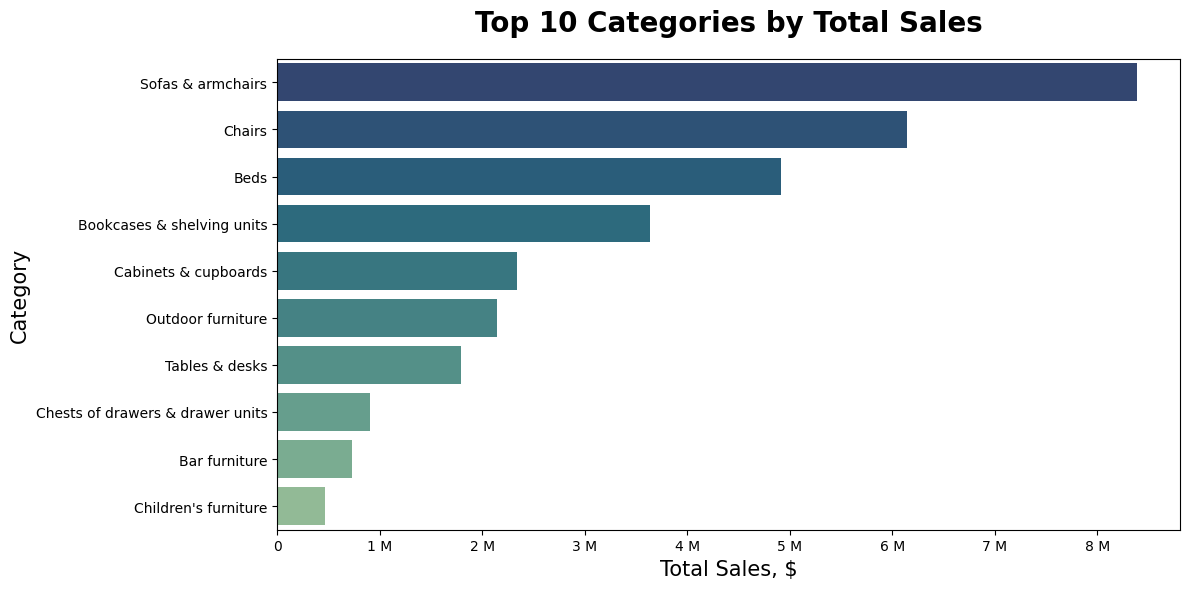

In [ ]:
plt.figure(figsize = (12, 6))

ax = sns.barplot(
    x = category_top.values,
    y = category_top.index,
    hue = category_top.index,
    palette = "crest_r"
)

plt.title("Top 10 Categories by Total Sales", size = 20, fontweight = "bold", pad = 20)
plt.xlabel("Total Sales, $", size = 15)
plt.ylabel("Category", size = 15)
plt.gca().xaxis.set_major_formatter(ticker.EngFormatter())

plt.style.use("ggplot")
plt.tight_layout()
plt.show()

***Графічне відображення отриманого результату щодо топ-10 категорій товарів за загальною сумою продажів***

### 3.3) Знайти топ-10 категорій товарів у країні з найбільшими продажами, перевірити чи відрізняється ситуація від загальної


In [ ]:
country_with_highest_sales = countries_top.index[0]
df_filter_top_country_by_price = df[df["country"] == country_with_highest_sales]

category_top_by_top_country = df_filter_top_country_by_price.groupby("category")["price"].sum().sort_values(ascending = False)

print(category_top_by_top_country.head(10))

category
Sofas & armchairs                   3707144.5
Chairs                              2619773.8
Beds                                2213058.0
Bookcases & shelving units          1567606.9
Cabinets & cupboards                 994545.5
Outdoor furniture                    929245.2
Tables & desks                       777865.0
Chests of drawers & drawer units     382388.0
Bar furniture                        330805.0
Children's furniture                 207575.0
Name: price, dtype: float64


Різниці, між даним топом для країни з найбільшими продажами та топом для всіх країн, немає. Всі категорії розставлені в ідентичному порядку.

Лідером є `Sofas & armchairs` ($3 707 144,5).

Найменшу суму в цьому топі має `Children's furniture` ($207 575).

### 3.4) Проаналізувати продажі у розрізі типів та моделей девайсів (у % від загальних продажів)

In [ ]:
total_sum = df["price"].sum()

In [ ]:
device_by_total_sum = (df.groupby("device")["price"].sum() / total_sum * 100).round(2).sort_values(ascending = False)
print(device_by_total_sum)

device
desktop    59.00
mobile     38.73
tablet      2.26
Name: price, dtype: float64


In [ ]:
mobile_model_name_by_total_sum = (df.groupby("mobile_model_name")["price"].sum() / total_sum * 100).round(2).sort_values(ascending = False)
print(mobile_model_name_by_total_sum)

mobile_model_name
Chrome        27.84
<Other>       20.44
Safari        20.30
iPhone        20.08
ChromeBook     5.73
Edge           2.18
iPad           1.40
Firefox        1.32
Pixel 4 XL     0.37
Pixel 3        0.34
Name: price, dtype: float64


Можемо бачити, що основним девайсом по % загальному продажу є `desktop` (59%), найменший показник від загального у `tablet` (2.26%)

Якщо переглянути моделі девайсів (та браузерів для комп'ютерів), то можемо побачити що фаворитом є `Chrome` (27.84%) а найменший показник має `Pixel 3` (0.34%) від загальної суми.

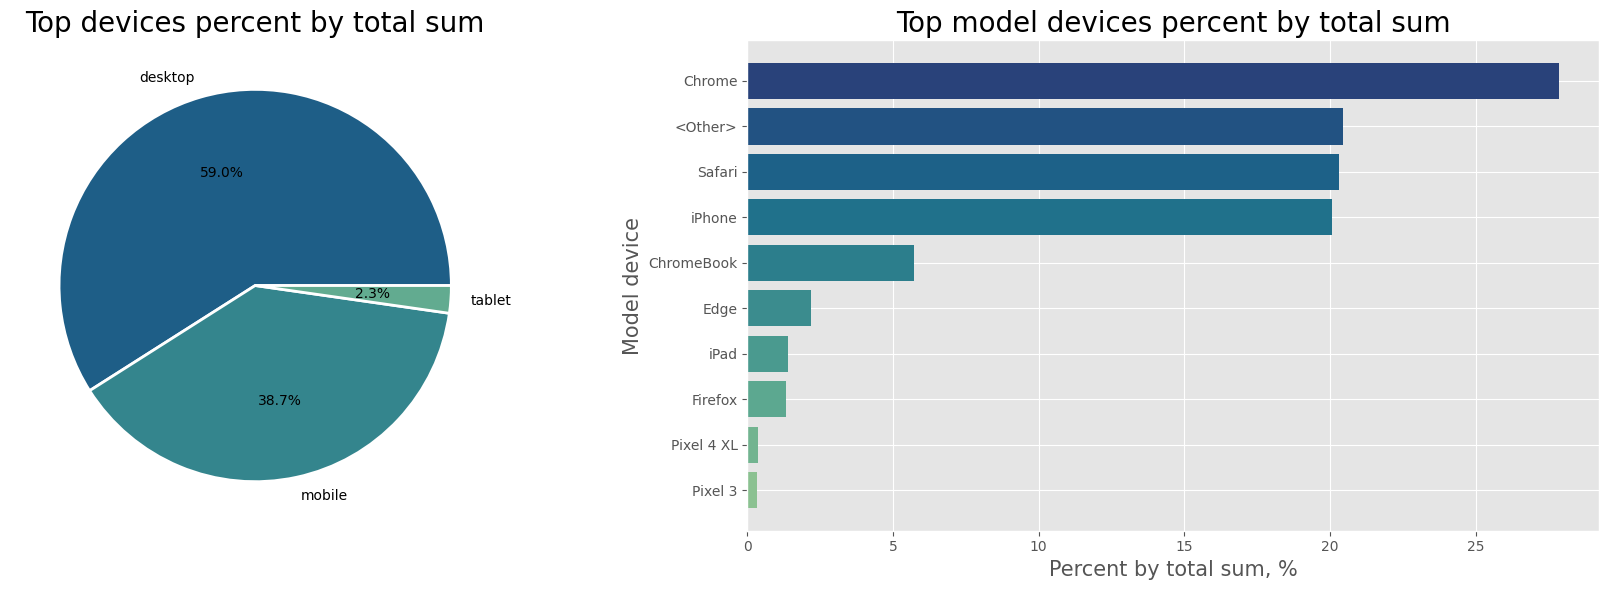

In [ ]:
fig, ax = plt.subplots(1, 2, figsize = (18, 6))


# first
ax[0].pie(data = device_by_total_sum, x = device_by_total_sum.values, labels = device_by_total_sum.index, wedgeprops = {"edgecolor": "white", "linewidth": 2}, autopct = "%1.1f%%",
          colors = sns.color_palette("crest_r", len(device_by_total_sum)))
ax[0].set_title("Top devices percent by total sum", size = 20)

# second

top_models = mobile_model_name_by_total_sum.head(10).iloc[::-1]

ax[1].barh(data = top_models,
    y = top_models.index,
    width = top_models.values,
    color = sns.color_palette("crest", len(top_models))
)
ax[1].set_title("Top model devices percent by total sum", size = 20)
ax[1].set_xlabel("Percent by total sum, %", size = 15)
ax[1].set_ylabel("Model device", size = 15)


plt.tight_layout()

plt.style.use("ggplot")
plt.show()

***Графічне відображення отриманого результату щодо продаж у розрізі типів та моделей девайсів (у % від загальних продажів)***

### 3.5) Проаналізувати продажі за джерелами трафіку (у % від загальних продажів)

In [ ]:
traffic_source_by_total_sum = (df.groupby("traffic_source_name")["price"].sum() / total_sum * 100).round(2).sort_values(ascending = False)
print(traffic_source_by_total_sum)

traffic_source_name
(organic)         34.20
(direct)          23.44
<Other>           18.45
(referral)        17.65
(data deleted)     6.26
Name: price, dtype: float64


Можемо бачити, що основним джерелом трафіку по % від загальних продаж є `organic` (34,2%), найменший показник від загального у видалених даних `data deleted` (6.26%)

### 3.6) Визначити який відсоток зареєстрованих користувачів підтвердив свою електронну адресу


In [ ]:
total_registered = df["account_id"].nunique()
acc_is_verif = df[df["is_verified"] == 1]
percent_acc_is_verif = round(acc_is_verif["account_id"].nunique() / total_registered * 100, 2)
print(f"Percent registered users with verified email addresses: {percent_acc_is_verif}%")

Percent registered users with verified email addresses: 71.7%


Можемо бачити, що `71.7%` зареєстрованих користувачів, підтвердили свою електронну адресу.

### 3.7) Визначити який відсоток зареєстрованих користувачів відписався від розсилки

In [ ]:
acc_is_unsubscribed = df[df["is_unsubscribed"] == 1]
percent_acc_is_unsubscribed = round(acc_is_unsubscribed["account_id"].nunique() / total_registered * 100, 2)
print(f"Percent registered users who unsubscribed: {percent_acc_is_unsubscribed}%")

Percent registered users who unsubscribed: 16.94%


Тобто можемо бачити, що `16,94%` зареєстрованих користувачів, відписались від розсилки.

### 3.8) Визначити чи відрізняється поведінка (у плані продажів) тих, хто відписався від розсилки та тих, хто досі підписаний


In [ ]:
sub_and_unsub = (df.groupby("is_unsubscribed")["price"].agg(["mean","median", "count"])).round(2)
sub_and_unsub = sub_and_unsub.rename(index = {0: "Subscribed", 1: "Unsubscribed"})
print(f"the difference between subscribed and unsubscribed:\n {sub_and_unsub}")

the difference between subscribed and unsubscribed:
                    mean  median  count
is_unsubscribed                       
Subscribed       921.51   395.0   2334
Unsubscribed     965.82   450.0    447


Можемо бачити, що приблизно `80%` від усієї кількості покупок, зареєстрованих користувачів, роблять ті хто досі підписані на розсилки, це `2334`, решту роблять ті хто відписався `447`. Медіане значення ціни більше у тих хто відписався (`450`) ніж у тих хто досі підписаний (`395`). Така сама ситуація і з показниками середнього значення (`965` та `921`).

Дивлячись на те що медіане значення в тих хто підписаний і ні, менше чим їх середні значення, це нам говорить про те, що цей діапазон значень ціни має нерівномірний розподіл, основна кількість значень знаходиться в лівій частині. Тобто маємо хвіст праворуч на графіку розподілу по кількості.

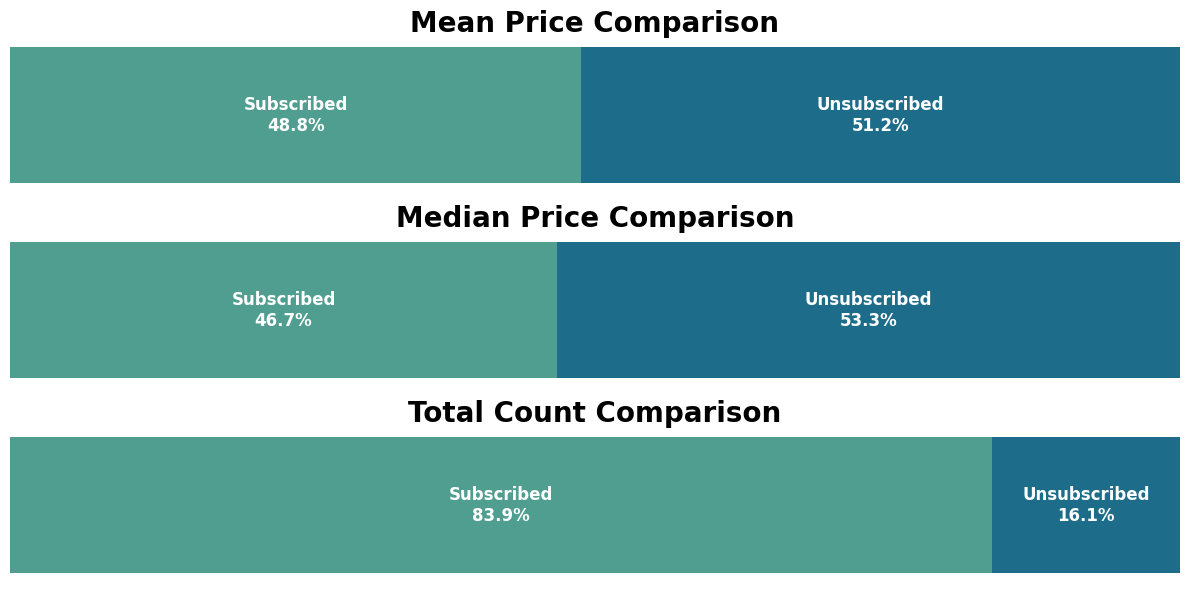

In [ ]:
fig, ax = plt.subplots(3, 1, figsize = (12, 6))

metrics = sub_and_unsub.columns
titles = ["Mean Price Comparison", "Median Price Comparison", "Total Count Comparison"]

colors = sns.color_palette("crest", 2)

for i, metric in enumerate(metrics):

    sub_val = sub_and_unsub.loc['Subscribed', metric]
    unsub_val = sub_and_unsub.loc['Unsubscribed', metric]

    total = sub_val + unsub_val
    sub_pct = (sub_val / total) * 100
    unsub_pct = (unsub_val / total) * 100


    ax[i].barh(y = 0, width = sub_pct, color = colors[0])
    ax[i].barh(y = 0, width = unsub_pct, left = sub_pct, color = colors[1])

    ax[i].set_title(titles[i], fontsize = 20, fontweight = "bold")
    ax[i].set_xlim(0, 100)
    ax[i].axis("off")

    sub_text = f"Subscribed\n{sub_pct:.1f}%"
    unsub_text = f"Unsubscribed\n{unsub_pct:.1f}%"

    # Додаємо текстові підписи з відсотками всередину блоків
    ax[i].text(x = sub_pct / 2, y = 0, s = sub_text, ha = "center", va = "center", color = "white", fontweight = "bold", fontsize = 12)
    ax[i].text(x = sub_pct + (unsub_pct / 2), y = 0, s = unsub_text, ha = "center", va = "center", color = "white", fontweight = "bold", fontsize = 12)

plt.style.use("ggplot")
plt.tight_layout()
plt.show()

***Графічне відображення отриманого результату у плані продажів тих, хто відписався від розсилки та тих, хто досі підписаний (% співвідношення)***

### 3.9) Визначити в яких країнах найбільше зареєстрованих користувачів

In [ ]:
print(df["account_id"].nunique())

27945


In [ ]:
top_countries_by_acc = df.groupby("country")["account_id"].nunique().sort_values(ascending = False)
print(top_countries_by_acc)

country
United States        12384
India                 2687
Canada                2067
United Kingdom         859
France                 553
                     ...  
Honduras                 4
Paraguay                 4
Mongolia                 4
Trinidad & Tobago        4
Bahrain                  2
Name: account_id, Length: 108, dtype: int64


Можемо бачити що топ 5 країн з найбільшою кількістю зареєстрованих користувачів:
* ***United State***s - `12 384`
* ***India*** - `2 687`
* ***Canada*** - `2 067`
* ***United Kingdom*** - `859`
* ***France*** - `553`

Також із даних топ-5 країн бачимо, що ***United States*** займає абсолютну більшість (близько 67% від лідерів), що чітко демонструє головний цільовий ринок цього інтернет-магазину.

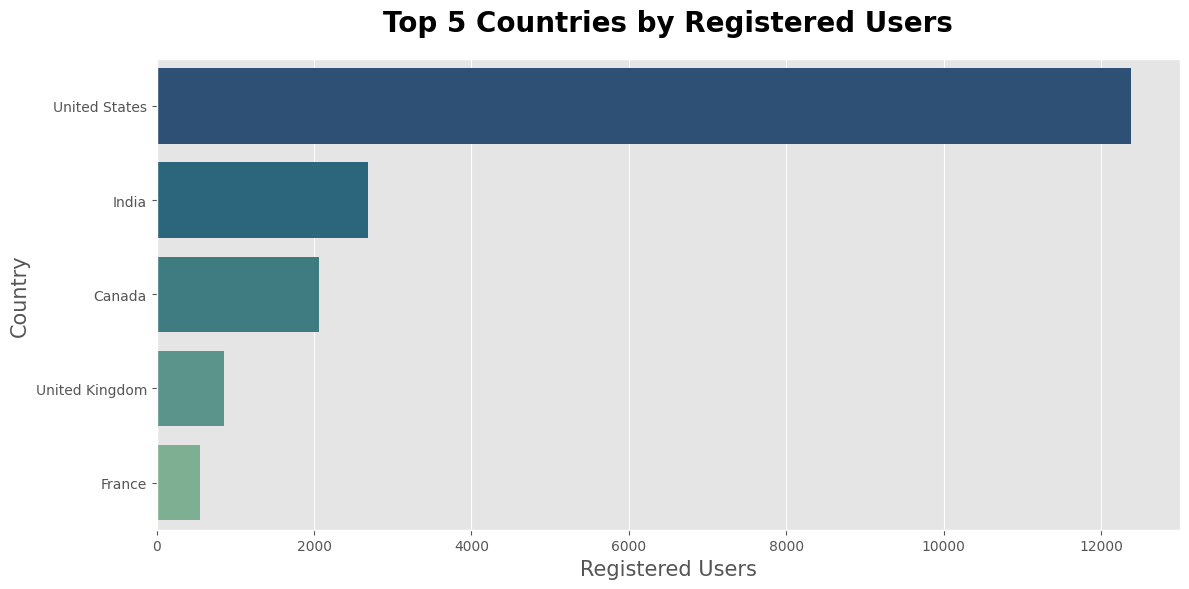

In [ ]:
plt.figure(figsize = (12, 6))

ax = sns.barplot(
    x = top_countries_by_acc.head().values,
    y = top_countries_by_acc.head().index,
    hue = top_countries_by_acc.head().index,
    palette = "crest_r",
)

plt.title("Top 5 Countries by Registered Users", size = 20, fontweight = "bold", pad = 20)
plt.xlabel("Registered Users", size = 15)
plt.ylabel("Country", size = 15)
plt.style.use("ggplot")

plt.tight_layout()
plt.show()

***Графічне відображення отриманого результату щодо інофрмації в яких країнах найбільше зареєстрованих користувачів***

# 4) Analysis of Sales Trends

### 4.1) Знайти загальні продажі за кожну дату, створити візуалізацію загальної динаміки продажів


In [ ]:
df_copy = df.copy()
df_sales = df.copy()

df_sales["date"] = pd.to_datetime(df_sales["date"])

dates_to_exclude = pd.to_datetime(["2021-01-28", "2021-01-29", "2021-01-30", "2021-01-31"])

df_sales = df_sales[~df_sales["date"].isin(dates_to_exclude)]

In [ ]:
df_sales.info()

<class 'pandas.core.frame.DataFrame'>
Index: 336076 entries, 0 to 349543
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   date                 336076 non-null  datetime64[ns]
 1   session_id           336076 non-null  Int64         
 2   continent            336076 non-null  object        
 3   country              336076 non-null  object        
 4   device               336076 non-null  object        
 5   browser              336076 non-null  object        
 6   mobile_model_name    336076 non-null  object        
 7   operating_system     336076 non-null  object        
 8   language             336076 non-null  object        
 9   traffic_source_name  336076 non-null  object        
 10  channel              336076 non-null  object        
 11  account_id           27945 non-null   Int64         
 12  is_verified          27945 non-null   Int64         
 13  is_unsubscribed    

In [ ]:
total_sales_per_date = df_sales.groupby("date")["price"].sum()
print(total_sales_per_date)

date
2020-11-01    244292.5
2020-11-02    355506.8
2020-11-03    498979.6
2020-11-04    339187.1
2020-11-05    391276.6
                ...   
2021-01-23    290605.5
2021-01-24    243818.4
2021-01-25    305089.3
2021-01-26    372057.3
2021-01-27    286340.7
Name: price, Length: 88, dtype: float64


In [ ]:
print(total_sales_per_date.sort_values(ascending = False))

date
2020-12-08    680509.5
2020-12-10    624104.6
2021-01-06    609763.8
2020-12-16    553134.9
2020-12-09    551811.6
                ...   
2020-11-08    221162.5
2021-01-01    217984.9
2020-11-14    214889.3
2020-11-15    209535.5
2020-11-07    200892.2
Name: price, Length: 88, dtype: float64


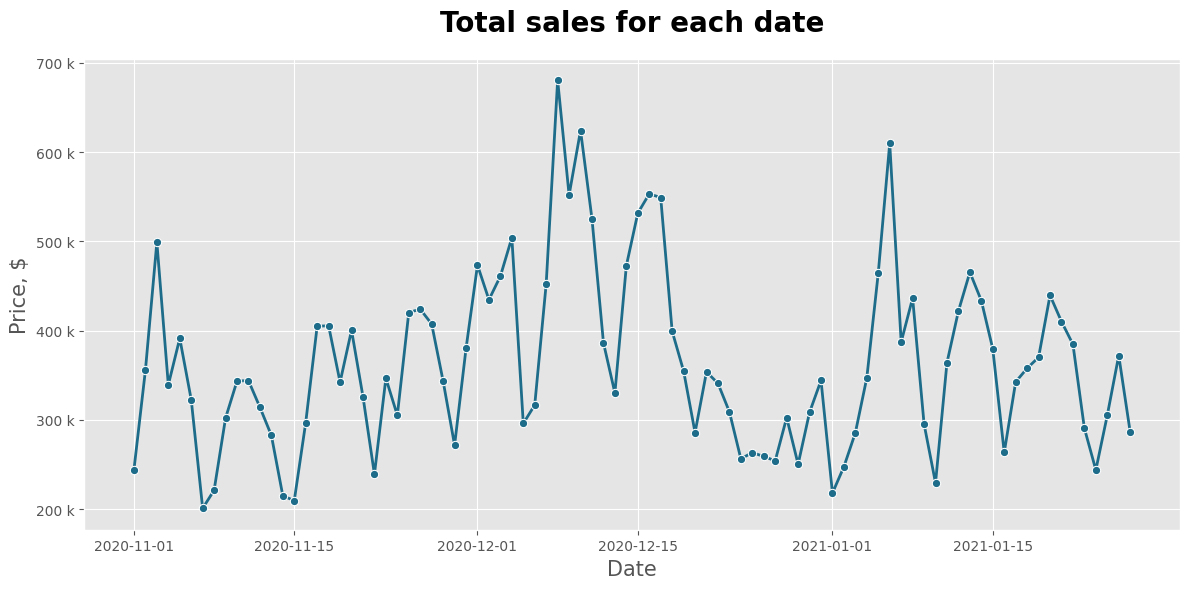

In [ ]:
plt.figure(figsize = (12, 6))

ax = sns.lineplot(
    x = total_sales_per_date.index,
    y = total_sales_per_date.values,
    color = sns.color_palette("crest_r", 2)[0],
    linewidth = 2,
    marker = "o"
)

plt.title("Total sales for each date", size = 20, fontweight = "bold", pad = 20)
plt.xlabel("Date", size = 15)
plt.ylabel("Price, $", size = 15)
plt.gca().yaxis.set_major_formatter(ticker.EngFormatter())

plt.style.use("ggplot")
plt.tight_layout()
plt.show()

Можемо бачити, що є основний діапазон загальних сум продажу, від `200 k` до `500 k`. Майже всі дні знаходяться в цьому діапазоні. Є три дні з піковими значеннями, які виділяються з загального діапазону, це:
* **2020-12-08** - `680 509.5`
* **2020-12-10** - `624 104.6`
* **2021-01-06** - `609 763.8`

Також були 4 дні, де дані про загальний заробіток були відсутні:
* **2021-01-31**
* **2021-01-30**
* **2021-01-29**
* **2021-01-28**

У ці дні фіксуються сесії, однак замовлення відсутні. Це свідчить про відсутність даних у джерелі, а не про нульові продажі. З метою уникнення спотворення результатів аналізу продаж ці дні було виключено з подальшого аналізу продажів. Перевірка підтвердила, що дані, за вказані дати, були відсутні ще до завантаження в поточний нотбук.

Також, можна помітити поступовий ріст по середину грудня 2020 (до `$624 104`), а потім, до початку січня 2021 року, бачимо негативний тренд (до `$210 000`), потім, в межах січня, знову локальний пік суми (2021-01-06 - `$609 763.8`), і значення далі залишаються в загальному діапазоні з певним позитивним трендом, відносно початку січня 2021.

З огляду на коротку тривалість наявних даних, робити висновки про сезонність продажів, наразі некоректно. Спостережувана динаміка (зростання в грудні та спад на початку січня) може бути пов’язана з передсвятковим періодом, однак для підтвердження сезонних продажів, потрібен більший діапазон часу для порівняння та розуміння повної картини даних.

### 4.2) Проаналізувати динаміку продажів в Америці, Азії та Європі, відобразити різні континенти різними кольорами

In [ ]:
df_sales["continent"].unique()

array(['(not set)', 'Asia', 'Africa', 'Europe', 'Oceania', 'Americas'],
      dtype=object)

In [ ]:
mask_a_a_e_continent = df_sales[df_sales["continent"].isin(["Americas", "Asia", "Europe"])]
sales_trends_by_3_continets = mask_a_a_e_continent.groupby(["date","continent"])["price"].sum().reset_index()

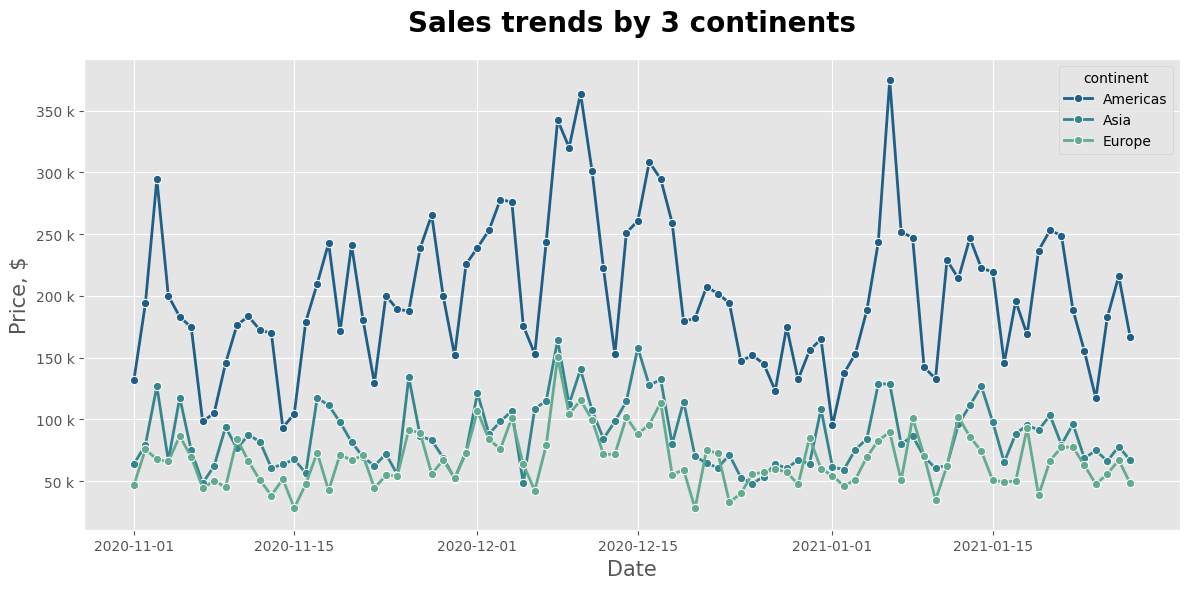

In [ ]:
plt.figure(figsize = (12, 6))

sns.lineplot(
    data = sales_trends_by_3_continets,
    x = "date",
    y = "price",
    hue = "continent",
    palette = "crest_r",
    linewidth = 2,
    marker = "o"
)

plt.title("Sales trends by 3 continents", size = 20, fontweight = "bold", pad = 20)
plt.xlabel("Date", size = 15)
plt.ylabel("Price, $", size = 15)
plt.gca().yaxis.set_major_formatter(ticker.EngFormatter())

plt.style.use("ggplot")
plt.tight_layout()
plt.show()

Дивлячись на динаміку продажів у трьох різних континентах, бачимо що, рух тренду є майже однаковим для них усіх, схожий на загальну динаміку продажів. Саме ці 3 континента, скаладають більше `90%` від загальною суми продаж, тому і їх графіки є схожими. Знову маємо хвилястий але позитивний тренд до середині грудня 2020, а потім певний негативний тренд до початку січня 2021, і знову хвилясти позитивний тренд.

Американський континент тримається в діапазоні продаж від `$100 000` до `$300 000` в середньому, має 3 пікових значення, так як і в загальному графіку до всіх континтів разом. А Європейський й Азійський континент, тримаються в середньому в діапазоні від `$25 000` до `$ 130 000`. Також мають свої пікові значення як і в графіку до загальних результатів по всім континентам.

### 4.3) Проаналізувати динаміку продажів у розрізі каналів трафіку, відобразити різні канали різними кольорами


In [ ]:
df_sales["channel"].unique()

array(['Direct', 'Organic Search', 'Paid Search', 'Undefined',
       'Social Search'], dtype=object)

In [ ]:
sales_trends_by_channel = df_sales.groupby(["date", "channel"])["price"].sum().reset_index()

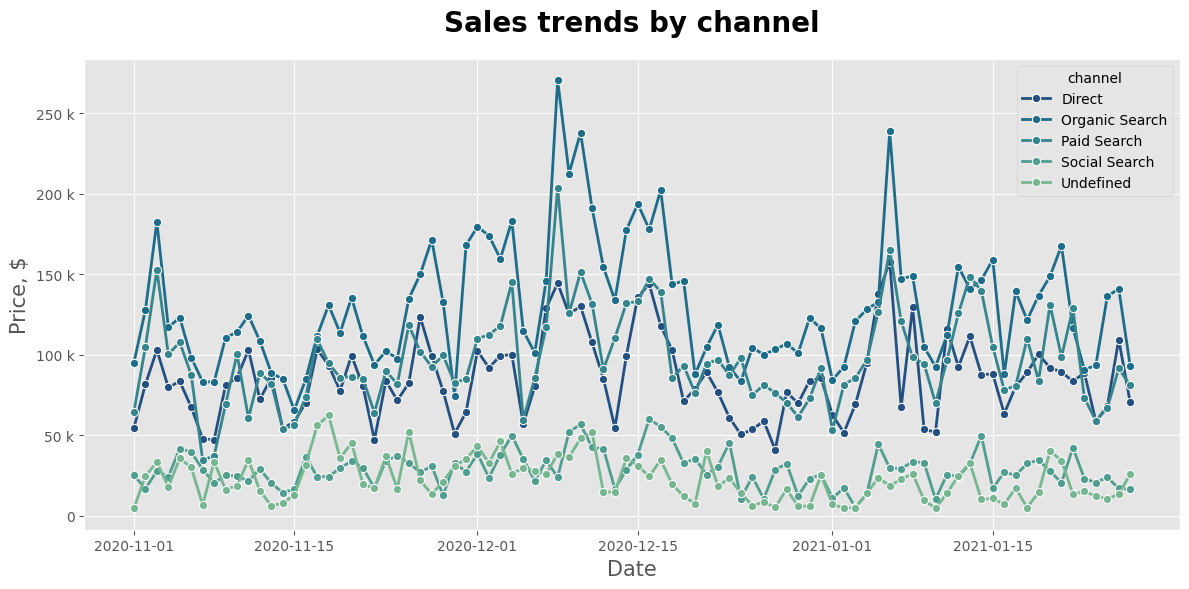

In [ ]:
plt.figure(figsize = (12, 6))

sns.lineplot(
    data = sales_trends_by_channel,
    x = "date",
    y = "price",
    hue = "channel",
    palette = "crest_r",
    linewidth = 2,
    marker = "o"
)

plt.title("Sales trends by channel", size = 20, fontweight = "bold", pad = 20)
plt.xlabel("Date", size = 15)
plt.ylabel("Price, $", size = 15)
plt.gca().yaxis.set_major_formatter(ticker.EngFormatter())

plt.style.use("ggplot")
plt.tight_layout()
plt.show()

Можемо бачити, що такі канали як: **Direct**, **Organic Search**, **Paid Search** мають динаміку, дуже схожу на загальний графік продажів. Також містять негативний тренд з середини грудня 2020 по початок січня 2021, також свої піки та тримаються одного діапазону продаж, а саме: `$50 000` по `$150 000`. Канали  **Social Search** та **Undefined** також містять цю закономірність, просто вона менше виражена і вони знаходяться в меншому діапазоні по продажам, а саме: `$0` до `$50 000`.

### 4.4) Проаналізувати динаміку продажів у розрізі типів девайсів, відобразити різні девайси різними кольорами


In [ ]:
df_sales["device"].unique()

array(['desktop', 'mobile', 'tablet'], dtype=object)

In [ ]:
sales_trends_by_device = df_sales.groupby(["date", "device"])["price"].sum().reset_index()

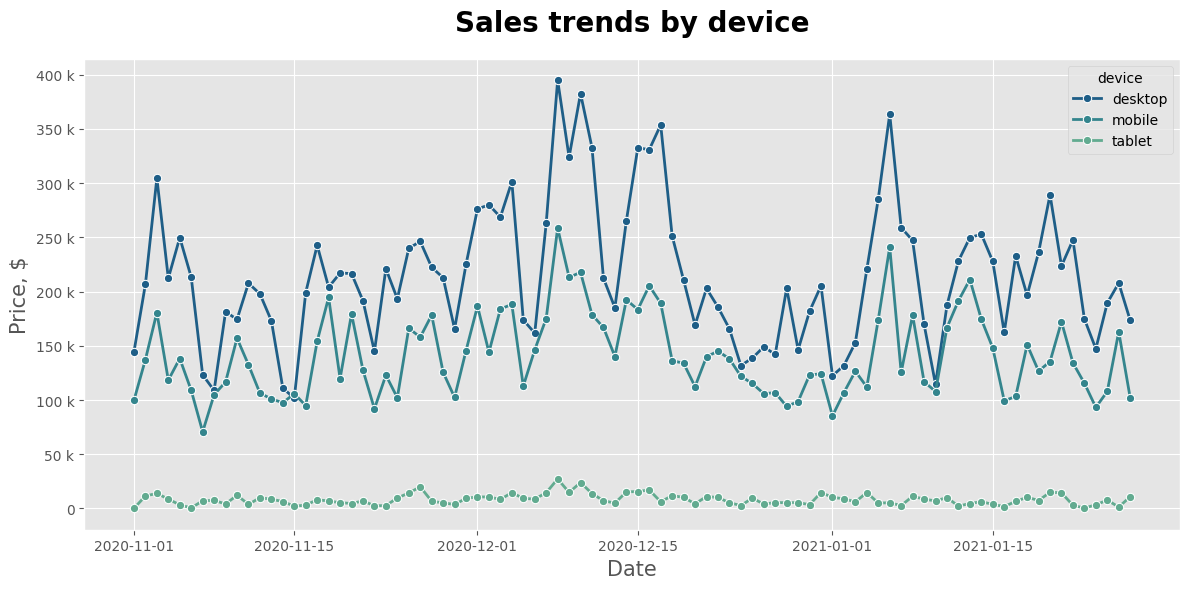

In [ ]:
plt.figure(figsize = (12, 6))

sns.lineplot(
    data = sales_trends_by_device,
    x = "date",
    y = "price",
    hue = "device",
    palette = "crest_r",
    linewidth = 2,
    marker = "o"
)

plt.title("Sales trends by device", size = 20, fontweight = "bold", pad = 20)
plt.xlabel("Date", size = 15)
plt.ylabel("Price, $", size = 15)
plt.gca().yaxis.set_major_formatter(ticker.EngFormatter())

plt.style.use("ggplot")
plt.tight_layout()
plt.show()

Для пристроїв, також можна помітити, що загальна тенденція з позитивними та негативними трендами збереглась. Знову позитивний тренд до середини грудня 2020, негативний тренд на кінець грудня 2020 та позитивний тренд на початок січня 2021.

Можемо побачити, що **Desktop**, **Mobile** знаходяться в діапазоні продаж від `$100 000` до `$270 000`, але також мають свої пікові значення, які більші за середній діапазон. **Tablet** також має загальну тенденцію, але знаходиться в діапазоні продаж, від `$0` до `$25 000`.

#5) Pivot tables

### 5.1) Cтворити зведену таблицю, яка показує кількість сесій у розрізі каналів трафіку та типів девайсів (якщо значення якогось поля невідоме, його не враховувати)

In [ ]:
df_copy["channel"].unique()

array(['Direct', 'Organic Search', 'Paid Search', 'Undefined',
       'Social Search'], dtype=object)

In [ ]:
df_filter = df_copy[df_copy["channel"] != "Undefined"]
pivot_session_count = df_filter.pivot_table(values = "session_id", index = "channel", columns = "device", aggfunc = "count").sort_values(by = "desktop", ascending = False)
print(pivot_session_count)

device          desktop  mobile  tablet
channel                                
Organic Search    72622   49014    2789
Paid Search       55167   37034    2140
Direct            47825   31745    1812
Social Search     16288   10988     638


Було створено зведену таблицю, та прибрано тип каналу - **Undefined**, так як, в дану категорію, вписувались всі канали які не визначені. Відповідно до умови задачі невідомі значення не враховуємо. В майбутньому, потрібно виправити це, щоб отримати повну картину всіх сесій в інтернет-магазині.

Бачимо, що для всіх трьох типів девайсів, фаворитним каналом трафіка є **Organic Search**:
* ***desktop*** - `72 622` сесій
* ***mobile*** - `49 014` сесій
* ***tablet*** - `2 789` сесій

А каналом з найменшою кількістю сесій є **Social Search**:
* ***desktop*** - `16 288` сесій
* ***mobile*** - `10 988` сесій
* ***tablet*** - `638` сесій

### 5.2) Створити зведену таблицю, яка показує загальні продажі за категоріями товарів (топ-10 категорій) у різних країнах (топ-5 країн)


In [ ]:
df_sales.head()

,date,session_id,continent,country,device,browser,mobile_model_name,operating_system,language,traffic_source_name,channel,account_id,is_verified,is_unsubscribed,item_id,category,product_name,price,short_description
0,2021-01-19,7268004754,(not set),(not set),desktop,Chrome,Chrome,Web,en-gb,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
1,2021-01-06,8321293308,(not set),(not set),desktop,Chrome,Chrome,Web,Unknown,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
2,2020-11-05,4392362373,(not set),(not set),desktop,Chrome,Chrome,Web,Unknown,(organic),Organic Search,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
3,2020-12-09,140108698,(not set),(not set),desktop,Chrome,Safari,Web,en-us,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
4,2020-11-10,8351127264,(not set),(not set),mobile,Safari,iPhone,Web,en-us,(organic),Organic Search,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None


In [ ]:

country_top_5 = df_sales.groupby("country")["price"].sum().sort_values(ascending = False).head().index
category_top_10 = df_sales.groupby("category")["price"].sum().sort_values(ascending = False).head(10).index

df_filter = df_sales[df_sales["country"].isin(country_top_5) & df_sales["category"].isin(category_top_10)]
pivot_total_sales_by_category_country = df_filter.pivot_table(values = "price", index = "category", columns = "country", aggfunc = "sum").sort_values(by = "United States", ascending = False)
pivot_total_sales_by_category_country


country,Canada,France,India,United Kingdom,United States
category,,,,,
Sofas & armchairs,692427.5,187735.0,788430.0,234812.0,3707144.5
Chairs,417740.8,134029.4,544309.2,188519.4,2619773.8
Beds,354772.0,116414.0,358319.5,133816.0,2213058.0
Bookcases & shelving units,278981.9,73830.0,364507.4,113987.6,1567606.9
Cabinets & cupboards,181802.0,59101.5,191888.0,71684.5,994545.5
Outdoor furniture,185322.8,40486.4,162289.4,57002.4,929245.2
Tables & desks,132678.0,42299.0,186157.5,49374.0,777865.0
Chests of drawers & drawer units,71952.0,21544.5,73111.0,36784.0,382388.0
Bar furniture,51724.0,11199.0,57657.0,22103.0,330805.0


Бачимо, що для всіх країн, фаворитною категорією є **Sofas & armchairs**:
* ***Canada*** - `$692 427.5`
* ***France*** - `$187 735`
* ***India*** - `$788 430`
* ***United Kingdom*** - `$234 812`
* ***United States*** - `$3 707 144.5`

А категорією товарів з найменшим загальним продажем є **Children's furniture**:
* ***Canada*** - `$30 264`
* ***France*** - `$14 258`
* ***India*** - `$39 177`
* ***United Kingdom*** - `$13 348`
* ***United States*** - `$207 575`

### 5.3) Створити зведену таблицю, яка показує загальні продажі у розрізі днів тижня та топ 5 країн по загальним продажам

In [ ]:
days = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

df_sales["day_of_week"] = pd.to_datetime(df_sales["date"]).dt.day_name()

df_filter_days = df_sales[df_sales["country"].isin(country_top_5)]

pivot_days_country = df_filter_days.pivot_table(values = "price", index = "day_of_week", columns = "country", aggfunc = "sum").reindex(days)

print(pivot_days_country)

country        Canada    France     India  United Kingdom  United States
day_of_week                                                             
Monday       366188.3  119254.1  393916.8        153827.0      2018236.4
Tuesday      371462.0  127297.0  483408.2        165177.5      2373250.7
Wednesday    416010.5   92524.2  489279.6        166000.8      2449078.4
Thursday     388510.1  129527.0  429264.5        120254.1      2181668.3
Friday       377796.6  116640.1  369043.2        136619.1      2012322.0
Saturday     294277.0   77693.0  282600.6         84765.0      1433117.1
Sunday       223676.5   47757.4  362249.1        111674.4      1475881.0


З даної таблиці, можемо бачити, що для кожної країни, загальні продажі мають негативний тренд на вихідних, відносно робочих днів. Для прикладу **United States** діапазон загальних продажів, протягом робочих днів, від `$2 012 322` до `$2 449 078` а у вихідні дні, від `$1 433 117` до `$1 475 881`.

# 6) Statistical Analysis of Correlations

### 6.1) Знайти кількість сесій та загальні продажі за кожну дату. Створити візуалізацію, щоб побачити взаємозв’язок між цими метриками. Визначити чи корелюють ці показники. Знайти відповідний коефіцієнт кореляції та проаналізувати його статистичну значущість.


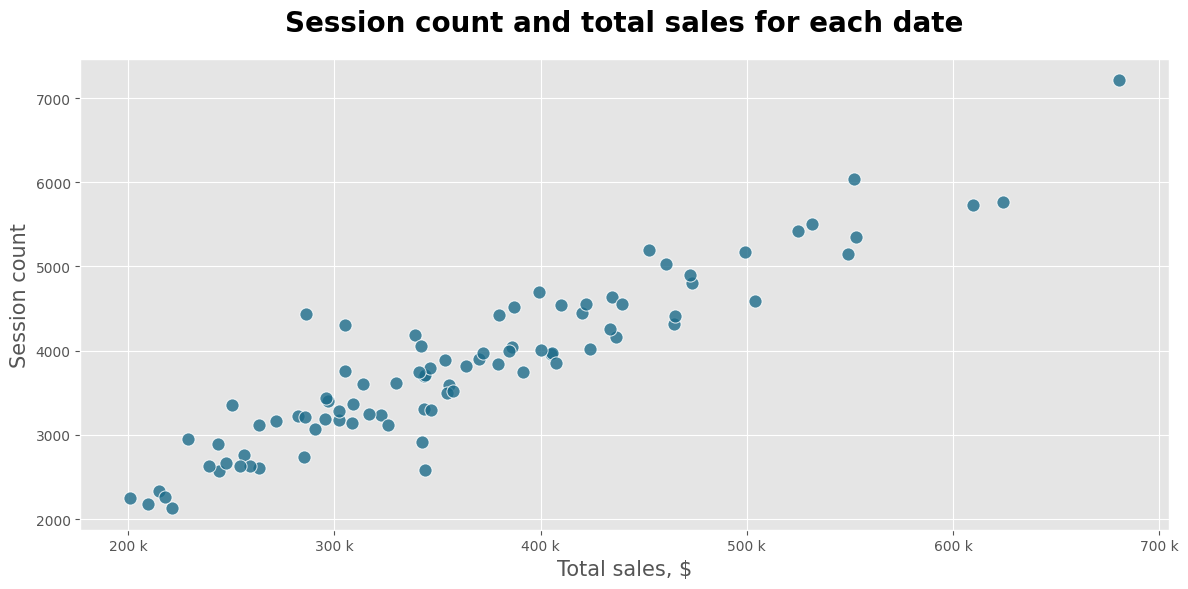

In [ ]:
total_session_sales_per_date = df_sales.groupby("date").agg(
    total_session = ("session_id", "nunique"), total_sales = ("price", "sum")).reset_index()

plt.figure(figsize = (12, 6))

sns.scatterplot(
    data = total_session_sales_per_date,
    x = "total_sales",
    y = "total_session",
    color = sns.color_palette("crest_r", 2)[0],
    s = 90,
    alpha = 0.8
)

plt.title("Session count and total sales for each date", size = 20, fontweight = "bold", pad = 20)
plt.xlabel("Total sales, $", size = 15)
plt.ylabel("Session count", size = 15)
plt.gca().xaxis.set_major_formatter(ticker.EngFormatter())

plt.style.use("ggplot")
plt.tight_layout()
plt.show()

З графічного відображення ми бачимо лінійну позитивну залежність між змінними.

In [ ]:
print("Shapiro test for sales:", scst.shapiro(total_session_sales_per_date["total_sales"]))
print("Shapiro test for sessions:", scst.shapiro(total_session_sales_per_date["total_session"]))

Shapiro test for sales: ShapiroResult(statistic=np.float64(0.9563431707174843), pvalue=np.float64(0.0047925668386651875))
Shapiro test for sessions: ShapiroResult(statistic=np.float64(0.9701004812858438), pvalue=np.float64(0.03948838648168485))


Можемо бачити що після перевірки на нормальний розподіл, продажі та сесії мають значення p_value < 0.05, що означає, що дані не мають нормального розподілу. Дивлячись на те що дані не мають нормального розподілу, один із наборів даних є дискретним (кількість сесій), тому для знаходження результату кореляції, було обрано **рангову кореляцію Спірмена**.

In [ ]:
correlation = total_session_sales_per_date["total_sales"].corr(total_session_sales_per_date["total_session"])#Пірсон
print(f"Correlation coefficient: {correlation:.4f}")

Correlation coefficient: 0.9313


In [ ]:
print(f"Test statistic and p-value: {scst.spearmanr(total_session_sales_per_date["total_sales"], total_session_sales_per_date["total_session"])}")

Test statistic and p-value: SignificanceResult(statistic=np.float64(0.904283047444613), pvalue=np.float64(1.5381769633064087e-33))


Після тесту **коефіцієнта кореляції Спірмена**, бачимо, що його значення між **total_sales** та **total_session**, за кожну дату, дорівнює `0.90`, що означає, що дані мають сильний прямий зв'язок. А значення p_value = `1.54e-33` є меншим чим `a = 0.05`, це означає, що взаємозвязок між загальними продажами та кількістю сесій є статистично значущим.

### 6.2) Визначити чи корелюють між собою продажі на різних континентах. Обрати топ-3 континенти. Проаналізувати статистичну значущість взаємозв’язків.

In [ ]:
print(continents_top.head(3))
continent_top_3 = continents_top.head(3).index
print(continent_top_3)

filter_df_top_con = df_sales[df_sales["continent"].isin(continent_top_3)]

           total_sales  order_count
continent                          
Americas    17665280.0        18553
Asia         7601298.3         7950
Europe       5934624.2         6261
Index(['Americas', 'Asia', 'Europe'], dtype='object', name='continent')


In [ ]:
pivot_corr_top_3_con = filter_df_top_con.pivot_table(values = "price", index = "date", columns = "continent", aggfunc = "sum")
pivot_corr_top_3_con.head()

continent,Americas,Asia,Europe
date,,,
2020-11-01,132002.5,63823.0,46908.0
2020-11-02,193861.0,79370.0,75710.8
2020-11-03,294529.8,126737.8,67692.0
2020-11-04,200009.5,66602.0,65915.0
2020-11-05,182988.2,117608.4,86540.0


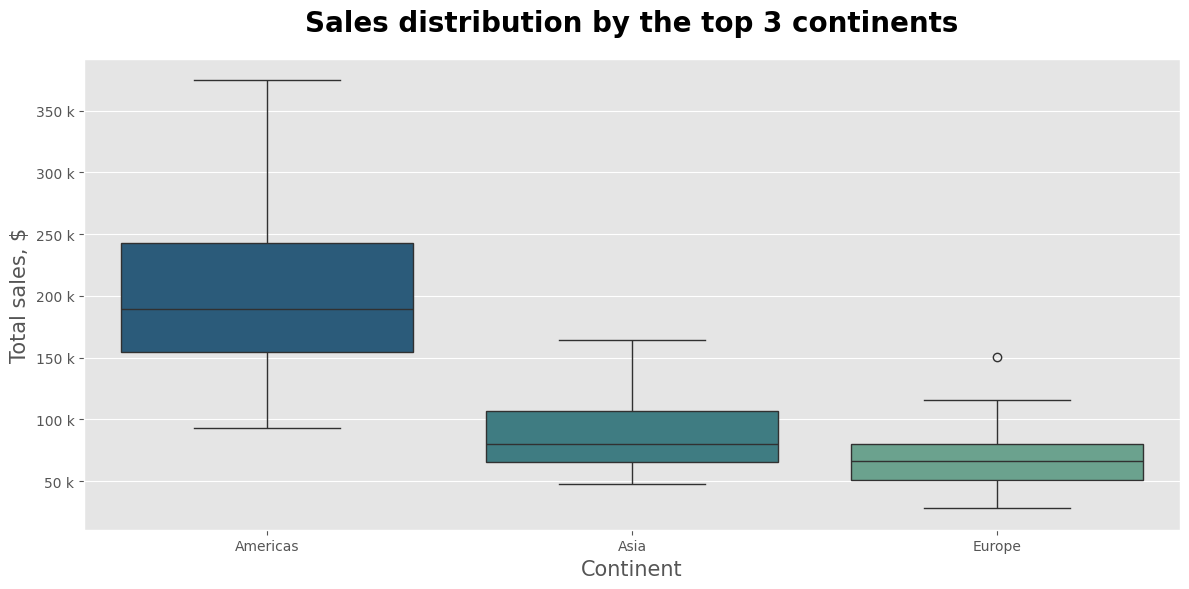

In [ ]:
plt.figure(figsize = (12, 6))
sns.boxplot(data = pivot_corr_top_3_con, palette = "crest_r")

plt.title("Sales distribution by the top 3 continents", size = 20, fontweight = "bold", pad = 20)
plt.xlabel("Continent", size = 15)
plt.ylabel("Total sales, $", size = 15)
plt.gca().yaxis.set_major_formatter(ticker.EngFormatter())

plt.style.use("ggplot")
plt.tight_layout()
plt.show()

На даному відображенню boxplot (міжквартальний діапазон IQR), можемо бачити:
* **Americas**
  * Медіана продажів - `$190 000`
  * Дуже довгий верхній вусик (приблизно `$370 000` - основний діапазон даних)

* **Asia**
  * Медіана продажів - `$80 000`

* **Europe**
  * Медіана продажів - `$70 000`
  * Є верхній викид - `$150 000`

Кольорові прямоктники показують наш міжквартальний розмах. Лінія всередині прямоктників, показує медіану.

In [ ]:
for continent in pivot_corr_top_3_con.columns:
    _, p_val = scst.shapiro(pivot_corr_top_3_con[continent])
    print(f"Continent - {continent}:\t")
    print(f"p_value = {p_val}")
    if (p_val < 0.05):
      print("The result is statistically significant, the data are not normally distributed")
    else:
      print("The data may be normally distributed")


Continent - Americas:	
p_value = 0.042468562628999736
The result is statistically significant, the data are not normally distributed
Continent - Asia:	
p_value = 0.0003820857396580246
The result is statistically significant, the data are not normally distributed
Continent - Europe:	
p_value = 0.007309892924070338
The result is statistically significant, the data are not normally distributed


Перевірка нормальності розподілу за критерієм **Шапіро–Уілка** показала, що продажі на всіх трьох континентах (**Americas, Asia, Europe**), не нормально розподілені, тобто p_value < `0.05`. Крім того, на **boxplot** виявлено викиди. У зв’язку з цим, для аналізу взаємозв’язків, між продажами на різних континентах, обрано непараметричний **коефіцієнт кореляції Спірмена**.

In [ ]:
print("Spearman")
for i in range(len(continent_top_3)):
    for j in range(i + 1, len(continent_top_3)):
        c1, c2 = continent_top_3[i], continent_top_3[j]

        corr_val, p_val = scst.spearmanr(pivot_corr_top_3_con[c1], pivot_corr_top_3_con[c2])

        print(f"Pair: {c1} - {c2}:")
        print(f"\t Correlation coefficient: {corr_val:.4f}")
        print(f"\t p_value: {p_val:.4e}")
        print(f"\t The result is statistically significant (p < 0.05): {p_val < 0.05}\n")

Spearman
Pair: Americas - Asia:
	 Correlation coefficient: 0.6685
	 p_value: 1.1001e-12
	 The result is statistically significant (p < 0.05): True

Pair: Americas - Europe:
	 Correlation coefficient: 0.6259
	 p_value: 7.0091e-11
	 The result is statistically significant (p < 0.05): True

Pair: Asia - Europe:
	 Correlation coefficient: 0.6082
	 p_value: 3.2731e-10
	 The result is statistically significant (p < 0.05): True



Дивлячись на p_value та величину кореляції, робимо висновок, що продажі на різних континетах мають статистично значущий помірний прямий зв'язок, так як p_value < 0.05 для кожної пари континентів та значення кореляції (correlation coefficient знаходиться в діапазоні від `0.608` до `0.668`)
Найбільший коефіцієнт кореляції має пара континентів: **Americas - Asia**, а саме `0.668`, а пара з найменшим коефіцієнтом кореляції, це: **Asia - Europe**, а саме `0.608`.

In [ ]:
corr_matrix_by_pearson = pivot_corr_top_3_con.corr() #Пірсон
print(corr_matrix_by_pearson)

continent  Americas      Asia    Europe
continent                              
Americas   1.000000  0.692273  0.669527
Asia       0.692273  1.000000  0.667786
Europe     0.669527  0.667786  1.000000


In [ ]:
corr_matrix_by_spearman = pivot_corr_top_3_con.corr(method = "spearman") #Спірмен
print(corr_matrix_by_spearman)

continent  Americas      Asia    Europe
continent                              
Americas   1.000000  0.668539  0.625885
Asia       0.668539  1.000000  0.608221
Europe     0.625885  0.608221  1.000000


Для порівняння також було розраховано коефіцієнти **Пірсона**. Вони виявилися вищими (`0.67–0.69`) за коефіцієнти **Спірмена**, на що повпливали викиди та ненормальність розподілу.

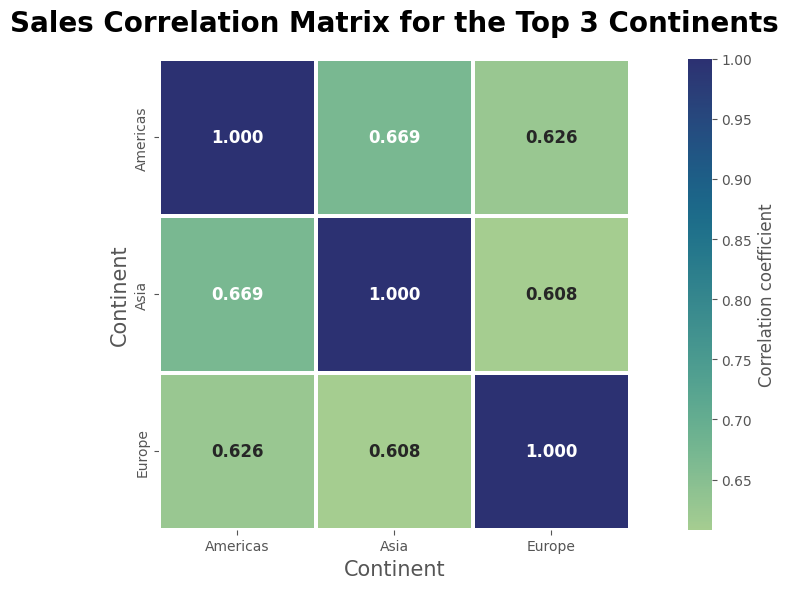

In [ ]:
plt.figure(figsize = (12, 6))

sns.heatmap(
    corr_matrix_by_spearman,
    annot = True,
    fmt = ".3f",
    cmap = "crest",
    linewidths = 1.5,
    square = True,
    annot_kws = {"size": 12, "weight": "bold"},
    cbar_kws = {"label": "Correlation coefficient"}
)

plt.title("Sales Correlation Matrix for the Top 3 Continents", size = 20, fontweight =  "bold", pad = 20)
plt.xlabel("Continent", size = 15)
plt.ylabel("Continent", size = 15)
plt.style.use("ggplot")
plt.tight_layout()
plt.show()

На матриці кореляції, можемо побачити помірний прямий (монотонний) взаємозв'язок між щоденними продажами на всіх трьох континентах (коефіцієнт кореляції, знаходиться в діапазоні від `0.608` до `0.669`).
Перевірка статистичної значущості показала, що для всіх пар континентів **p_value < 0.05**, що підтверджує те що, виявлений зв'язок є статистично значущим, а не випадковим збігом.

# 6.3) Визначити чи корелюють між собою продажі за різними каналами трафіку. Проаналізувати статистичну значущість взаємозв’язків.


In [ ]:
df_sales["channel"].unique()

array(['Direct', 'Organic Search', 'Paid Search', 'Undefined',
       'Social Search'], dtype=object)

In [ ]:
df_filter = df_sales[df_sales["channel"] != "Undefined"]

channel_filter = df_filter["channel"].unique()
print(channel_filter)

['Direct' 'Organic Search' 'Paid Search' 'Social Search']


In [ ]:
pivot_corr_by_channel = df_filter.pivot_table(values = "price", index = "date", columns = "channel", aggfunc = "sum")
pivot_corr_by_channel.head()

channel,Direct,Organic Search,Paid Search,Social Search
date,,,,
2020-11-01,54669.5,95112.0,64688.0,25078.0
2020-11-02,81561.5,127746.5,104780.8,16843.0
2020-11-03,102909.5,182521.9,152641.3,27652.5
2020-11-04,79683.6,117067.1,100332.0,24257.4
2020-11-05,83367.6,122938.4,107648.0,41693.2


In [ ]:
total_sales = df_sales["price"].sum()

undefined_sales = df_sales[df_sales["channel"] == "Undefined"]["price"].sum()

undefined_sales_percentage = (undefined_sales / total_sales) * 100

print(f"Total sales: {total_sales:,.2f}")
print(f"Total sales Undefined: {undefined_sales:,.2f}")
print(f"Percent total sales Undefined: {undefined_sales_percentage:.2f}%")

Total sales: 31,971,731.10
Total sales Undefined: 2,000,501.00
Percent total sales Undefined: 6.26%


Так як умовою задачі було перевірити саме чи корелюють продажі за різними каналами трафіку, тому було вирішено прибрати канал `Undefined` так як він є значенням каналу яке не можливо було визначити, скоріше за все автоматично. В майбутньому, потрібно виправити це, щоб отримати повну картину кореляції продаж за різними каналими трафіку.

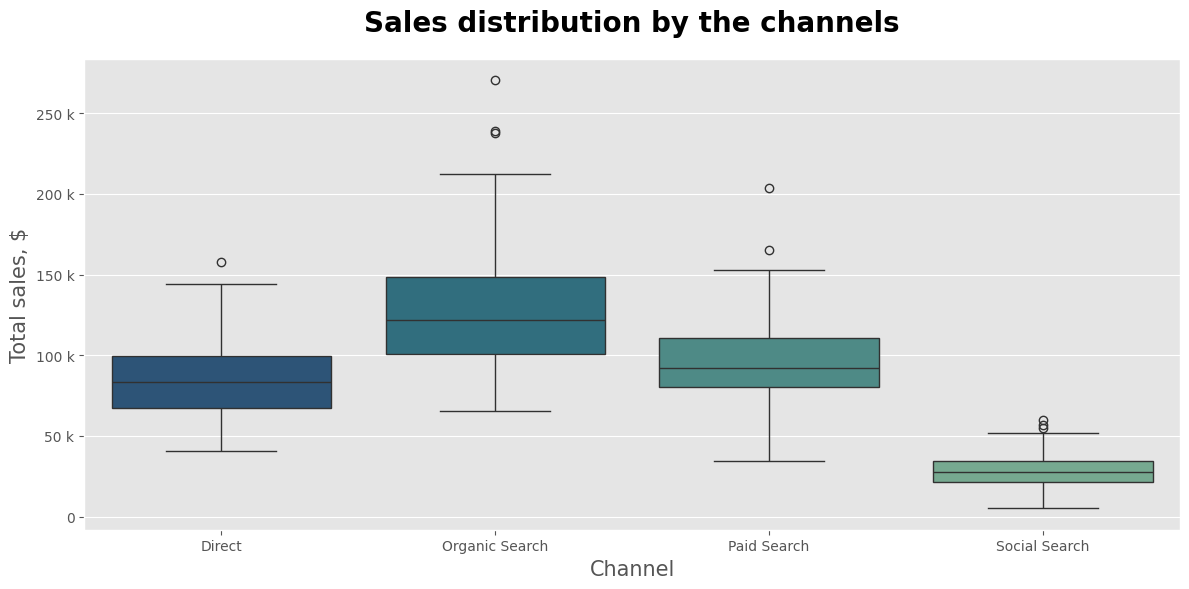

In [ ]:
plt.figure(figsize = (12, 6))
sns.boxplot(data = pivot_corr_by_channel, palette = "crest_r")

plt.title("Sales distribution by the channels", size = 20, fontweight = "bold", pad = 20)
plt.xlabel("Channel", size = 15)
plt.ylabel("Total sales, $", size = 15)
plt.gca().yaxis.set_major_formatter(ticker.EngFormatter())

plt.style.use("ggplot")
plt.tight_layout()
plt.show()

На даному відображенню boxplot (міжквартальний діапазон IQR), можемо бачити:
* **Direct**
  * Медіана продажів - `$80 000`
  * Верхній викид - `$160 000`

* **Organic Search**
  * Медіана продажів - `$125 000`
  * Декілька верхніх викидів - `$240 000` і `$280 000`

* **Paid Search**
  * Медіана продажів - `$90 000`
  * Декілька верхніх викидів - `$165 000` і `$205 000`

* **Social Search**
  * Медіана продажів - `$30 000`
  * Декілька верхніх викидів - `$55 000` і `$60 000`

Кольорові прямоктники показують наш міжквартальний розмах. Лінія всередині прямоктників, показує медіану.

In [ ]:
for channel in pivot_corr_by_channel.columns:
    _, p_val = scst.shapiro(pivot_corr_by_channel[channel])
    print(f"Channel - {channel}:\t")
    print(f"p_value = {p_val}")
    if (p_val < 0.05):
      print("The result is statistically significant, the data are not normally distributed")
    else:
      print("The data may be normally distributed")

Channel - Direct:	
p_value = 0.012486076318203962
The result is statistically significant, the data are not normally distributed
Channel - Organic Search:	
p_value = 9.599991143695942e-05
The result is statistically significant, the data are not normally distributed
Channel - Paid Search:	
p_value = 0.017435847676207643
The result is statistically significant, the data are not normally distributed
Channel - Social Search:	
p_value = 0.1130966509154806
The data may be normally distributed


Так як дані для каналів трафіку: **Direct, Organic Search, Paid Search**, не нормально розподілені, для каналу **Social Search** гіпотезу, про нормальність розподілу, відхилити не вдалося - p_value(`0.11`) > `0.05`, з графічного відображення (boxplot) ми бачимо, що в кожному каналі є викиди, тому вирішено обрати **рангову кореляцію Спірмена**.

In [ ]:
print("Spearman")
for i in range(len(channel_filter)):
    for j in range(i + 1, len(channel_filter)):
        c1, c2 = channel_filter[i], channel_filter[j]

        corr_val, p_val = scst.spearmanr(pivot_corr_by_channel[c1], pivot_corr_by_channel[c2])

        print(f"Pair: {c1} - {c2}:")
        print(f"\t Correlation coefficient: {corr_val:.4f}")
        print(f"\t p_value: {p_val:.4e}")
        print(f"\t The result is statistically significant (p < 0.05): {p_val < 0.05}\n")

Spearman
Pair: Direct - Organic Search:
	 Correlation coefficient: 0.7482
	 p_value: 5.3625e-17
	 The result is statistically significant (p < 0.05): True

Pair: Direct - Paid Search:
	 Correlation coefficient: 0.6908
	 p_value: 9.5055e-14
	 The result is statistically significant (p < 0.05): True

Pair: Direct - Social Search:
	 Correlation coefficient: 0.3937
	 p_value: 1.4783e-04
	 The result is statistically significant (p < 0.05): True

Pair: Organic Search - Paid Search:
	 Correlation coefficient: 0.7639
	 p_value: 4.8635e-18
	 The result is statistically significant (p < 0.05): True

Pair: Organic Search - Social Search:
	 Correlation coefficient: 0.3848
	 p_value: 2.1439e-04
	 The result is statistically significant (p < 0.05): True

Pair: Paid Search - Social Search:
	 Correlation coefficient: 0.4204
	 p_value: 4.5438e-05
	 The result is statistically significant (p < 0.05): True



Дивлячись на p_value та величину кореляції, робимо висновок, що загальні продажі між такими каналами як:
* **Direct - Organic Search** мають correlation coefficient: 0.748 та p_value - 5.36e-17
* **Direct - Paid Search** мають correlation coefficient: 0.69 та p_value - 9.5e-14
* **Organic Search - Paid Search** мають correlation coefficient: 0.763 та p_value - 4.86e-18

Тобто ці пари мають, статистично значущий сильний прямий зв'язок, так як p_value < 0.05 для кожної пари каналів та значення кореляції (correlation coefficient знаходиться в діапазоні від `0.69` до `0.76`)

А інші 3 пари, такі як:

* **Direct - Social Search** мають correlation coefficient: 0.39 та p_value - 1.48e-04
* **Organic Search - Social Search** мають correlation coefficient: 0.38 та p_value - 2.14e-04
* **Paid Search - Social Search** мають correlation coefficient: 0.42 та p_value - 4.54e-05

Тобто ці пари мають, статистично значущий помірний прямий зв'язок, так як p_value < 0.05 для кожної пари каналів та значення кореляції (correlation coefficient знаходиться в діапазоні від `0.38` до `0.42`)

Найбільший коефіцієнт кореляції має пара каналів: **Organic Search - Paid Search**, а саме `0.76`, а пара з найменшим коефіцієнтом кореляції, це: **Organic Search - Social Search**, а саме `0.38`.


Також можемо помітити що всі пари разом з **Social Search** мають менший рівень кореляції чим з іншими.

In [ ]:
corr_matrix_by_pearson = pivot_corr_by_channel.corr() #Пірсон
print(corr_matrix_by_pearson)

channel           Direct  Organic Search  Paid Search  Social Search
channel                                                             
Direct          1.000000        0.759938     0.724343       0.461895
Organic Search  0.759938        1.000000     0.808234       0.434424
Paid Search     0.724343        0.808234     1.000000       0.452287
Social Search   0.461895        0.434424     0.452287       1.000000


In [ ]:
corr_matrix_by_spearman = pivot_corr_by_channel.corr(method = "spearman") #Спірмен
print(corr_matrix_by_spearman)

channel           Direct  Organic Search  Paid Search  Social Search
channel                                                             
Direct          1.000000        0.748248     0.690782       0.393681
Organic Search  0.748248        1.000000     0.763922       0.384770
Paid Search     0.690782        0.763922     1.000000       0.420397
Social Search   0.393681        0.384770     0.420397       1.000000


Коефіцієнти **Пірсона** виявилися вищими: між каналами **Direct, Organic Search та Paid Search** вони становили `від 0.72 до 0.81`, а зв’язки із **Social Search** — у межах `від 0.43 до 0.46`.

Коефіцієнти Спірмена, має нищі показники кореляції: сильні зв’язки між основними каналами знаходяться в діапазоні `від 0.69 до 0.76`, а з **Social Search** — лише `від 0.38 до 0.42`. Оскільки дані більшості каналів не відповідають нормальному розподілу та містять викиди, основним методом інтерпретації обрано кореляцію **Спірмена**. Результати **Пірсона** наведено для порівняння.

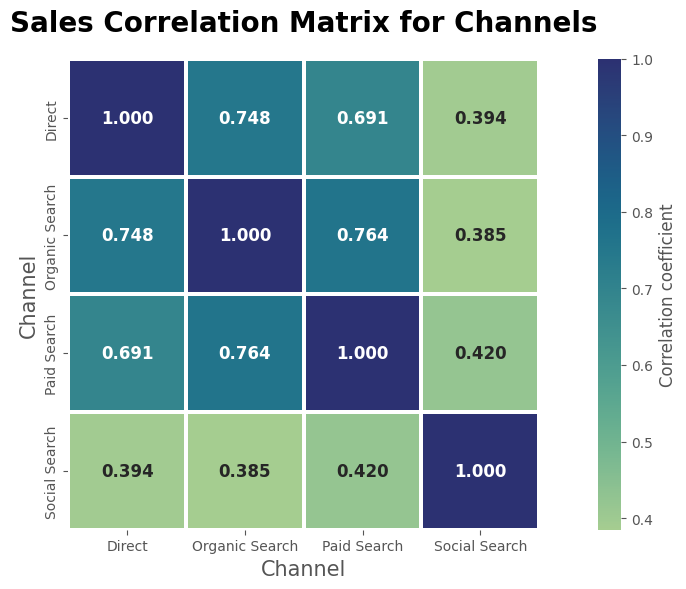

In [ ]:
plt.figure(figsize = (12, 6))

sns.heatmap(
    corr_matrix_by_spearman,
    annot = True,
    fmt = ".3f",
    cmap = "crest",
    linewidths = 1.5,
    square = True,
    annot_kws = {"size": 12, "weight": "bold"},
    cbar_kws = {"label": "Correlation coefficient"}
)

plt.title("Sales Correlation Matrix for Channels", size = 20, fontweight =  "bold", pad = 20)
plt.xlabel("Channel", size = 15)
plt.ylabel("Channel", size = 15)
plt.style.use("ggplot")
plt.tight_layout()
plt.show()

На матриці кореляції, можемо побачити сильний прямий (монотонний) взаємозв'язок (*коефіцієнт кореляції, знаходиться в діапазоні від 0.69 до 0.76*) та помірний прямий (монотоний) взаємозв'язок (*коефіцієнт кореляції, знаходиться в діапазоні від 0.38 до 0.42*) між щоденними продажами всіх каналів. Перевірка статистичної значущості показала, що для всіх пар каналів p_value < 0.05, що підтверджує те що, виявлені зв'язки є статистично значущими, а не випадковим збігом.

### 6.4) Визначити чи корелюють між собою продажі за топ-5 категоріями товарів. Проаналізувати статистичну значущість взаємозв’язків.


In [ ]:
category_top = df_sales.groupby("category")["price"].sum().sort_values(ascending = False).head().index
print(category_top)

Index(['Sofas & armchairs', 'Chairs', 'Beds', 'Bookcases & shelving units',
       'Cabinets & cupboards'],
      dtype='object', name='category')


In [ ]:
filter_df_top_categ = df_sales[df_sales["category"].isin(category_top)]

In [ ]:
pivot_corr_top_5_categ = filter_df_top_categ.pivot_table(values = "price", index = "date", columns = "category", aggfunc = "sum")
pivot_corr_top_5_categ.head()

category,Beds,Bookcases & shelving units,Cabinets & cupboards,Chairs,Sofas & armchairs
date,,,,,
2020-11-01,14041.0,36701.0,13591.5,46006.0,75216.0
2020-11-02,79683.5,40979.0,21623.0,58834.0,79977.5
2020-11-03,66219.5,64360.1,33555.5,61204.0,175594.0
2020-11-04,48939.0,35719.8,19266.0,44113.0,86861.5
2020-11-05,23449.0,40998.8,29235.0,90388.4,137288.0


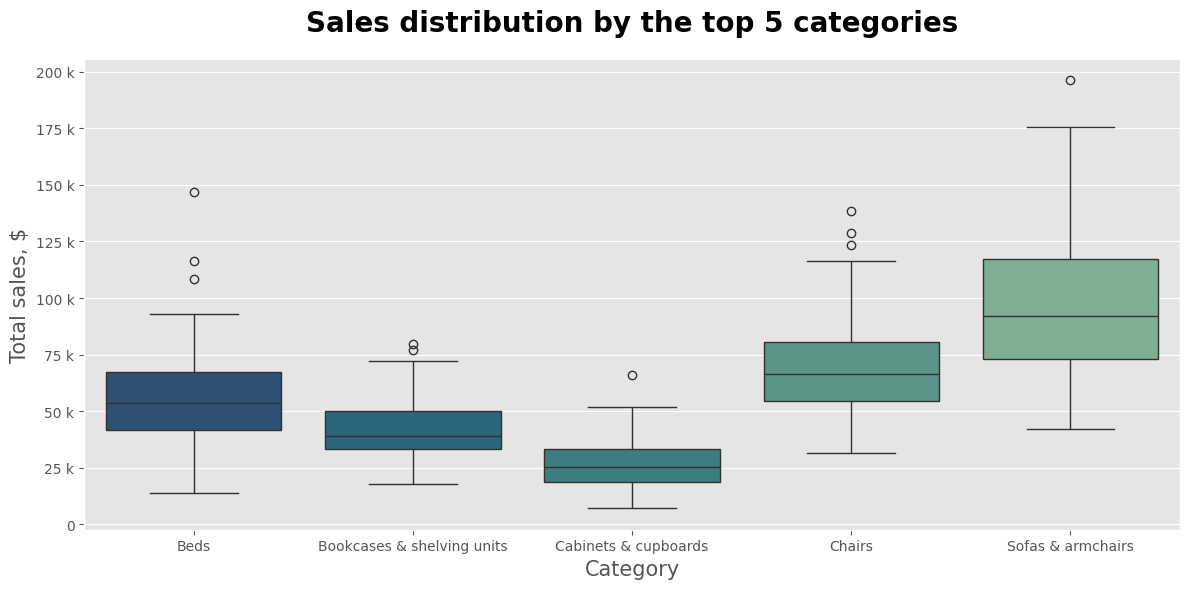

In [ ]:
plt.figure(figsize = (12, 6))
sns.boxplot(data = pivot_corr_top_5_categ, palette = "crest_r")

plt.title("Sales distribution by the top 5 categories", size = 20, fontweight = "bold", pad = 20)
plt.xlabel("Category", size = 15)
plt.ylabel("Total sales, $", size = 15)
plt.gca().yaxis.set_major_formatter(ticker.EngFormatter())

plt.style.use("ggplot")
plt.tight_layout()
plt.show()

На даному відображенню boxplot (міжквартальний діапазон IQR), можемо бачити:
* **Beds**
  * Медіана продажів - `$55 000`
  * Декілька верхніх викидів - `$110 000`, `$120 000`  і `$145 000`

* **Bookcases & shelving units**
  * Медіана продажів - `$35 000`
  * Декілька верхніх викидів - `$78 000` і `$80 000`

* **Cabinets & cupboards**
  * Медіана продажів - `$25 000`
  * Верхній викид - `$60 000`

* **Chairs**
  * Медіана продажів - `$65 000`
  * Декілька верхніх викидів - `$121 000`, `$130 000` і `$135 000`

* **Sofas & armchairs**
  * Медіана продажів - `$90 000`
  * Дуже довгий верхній вусик ($175 000 - основний діапазон даних)
  * Верхній викид - `$195 000`

Кольорові прямоктники показують наш міжквартальний розмах. Лінія всередині прямоктників, показує медіану.

In [ ]:
for category in pivot_corr_top_5_categ.columns:
    _, p_val = scst.shapiro(pivot_corr_top_5_categ[category])
    print(f"Category - {category}:\t")
    print(f"p_value = {p_val}")
    if (p_val < 0.05):
      print("The result is statistically significant, the data are not normally distributed")
    else:
      print("The data may be normally distributed")

Category - Beds:	
p_value = 0.001990313417105756
The result is statistically significant, the data are not normally distributed
Category - Bookcases & shelving units:	
p_value = 0.008807256782666481
The result is statistically significant, the data are not normally distributed
Category - Cabinets & cupboards:	
p_value = 0.004672141747344718
The result is statistically significant, the data are not normally distributed
Category - Chairs:	
p_value = 0.0007083935880594534
The result is statistically significant, the data are not normally distributed
Category - Sofas & armchairs:	
p_value = 0.012167254393811892
The result is statistically significant, the data are not normally distributed


Перевірка нормальності розподілу за критерієм **Шапіро–Уілка** показала, що продажі у всіх категоріях (**Sofas & armchairs, Chairs, Beds, Bookcases & shelving units, Cabinets & cupboards**), не нормально розподілені, тобто p_value < `0.05`. Крім того, на **boxplot** виявлено викиди. У зв’язку з цим, для аналізу взаємозв’язків, між продажами у різних категоріях, обрано непараметричний **коефіцієнт кореляції Спірмена**.

In [ ]:
print("Spearman")
for i in range(len(category_top)):
    for j in range(i + 1, len(category_top)):
        c1, c2 = category_top[i], category_top[j]

        corr_val, p_val = scst.spearmanr(pivot_corr_top_5_categ[c1], pivot_corr_top_5_categ[c2])

        print(f"Pair: {c1} - {c2}:")
        print(f"\t Correlation coefficient: {corr_val:.4f}")
        print(f"\t p_value: {p_val:.4e}")
        print(f"\t The result is statistically significant (p < 0.05): {p_val < 0.05}\n")

Spearman
Pair: Sofas & armchairs - Chairs:
	 Correlation coefficient: 0.5833
	 p_value: 2.4628e-09
	 The result is statistically significant (p < 0.05): True

Pair: Sofas & armchairs - Beds:
	 Correlation coefficient: 0.5217
	 p_value: 1.8644e-07
	 The result is statistically significant (p < 0.05): True

Pair: Sofas & armchairs - Bookcases & shelving units:
	 Correlation coefficient: 0.6256
	 p_value: 7.1890e-11
	 The result is statistically significant (p < 0.05): True

Pair: Sofas & armchairs - Cabinets & cupboards:
	 Correlation coefficient: 0.6312
	 p_value: 4.3229e-11
	 The result is statistically significant (p < 0.05): True

Pair: Chairs - Beds:
	 Correlation coefficient: 0.5349
	 p_value: 7.9134e-08
	 The result is statistically significant (p < 0.05): True

Pair: Chairs - Bookcases & shelving units:
	 Correlation coefficient: 0.6368
	 p_value: 2.5854e-11
	 The result is statistically significant (p < 0.05): True

Pair: Chairs - Cabinets & cupboards:
	 Correlation coefficient:

Дивлячись на p_value та величину кореляції, робимо висновок, що загальні продажі в різних категоріях мають статистично значущий помірний прямий зв'язок, так як p_value < 0.05 для кожної пари категорій та значення кореляції (correlation coefficient знаходиться в діапазоні від `0.440` до `0.637`)
Найбільший коефіцієнт кореляції має пара категорій: **Chairs - Bookcases & shelving units**, а саме `0.637`, а пара з найменшим коефіцієнтом кореляції, це: **Beds - Cabinets & cupboards**, а саме `0.440`.

In [ ]:
corr_matrix_by_pearson = pivot_corr_top_5_categ.corr() #Пірсон
print(corr_matrix_by_pearson)

category                        Beds  Bookcases & shelving units  \
category                                                           
Beds                        1.000000                    0.592913   
Bookcases & shelving units  0.592913                    1.000000   
Cabinets & cupboards        0.514609                    0.539428   
Chairs                      0.554500                    0.637090   
Sofas & armchairs           0.535378                    0.666194   

category                    Cabinets & cupboards    Chairs  Sofas & armchairs  
category                                                                       
Beds                                    0.514609  0.554500           0.535378  
Bookcases & shelving units              0.539428  0.637090           0.666194  
Cabinets & cupboards                    1.000000  0.572870           0.657563  
Chairs                                  0.572870  1.000000           0.578248  
Sofas & armchairs                       0.6

In [ ]:
corr_matrix_by_spearman = pivot_corr_top_5_categ.corr(method = "spearman") #Спірмен
print(corr_matrix_by_spearman)

category                        Beds  Bookcases & shelving units  \
category                                                           
Beds                        1.000000                    0.542742   
Bookcases & shelving units  0.542742                    1.000000   
Cabinets & cupboards        0.440368                    0.528706   
Chairs                      0.534941                    0.636751   
Sofas & armchairs           0.521715                    0.625603   

category                    Cabinets & cupboards    Chairs  Sofas & armchairs  
category                                                                       
Beds                                    0.440368  0.534941           0.521715  
Bookcases & shelving units              0.528706  0.636751           0.625603  
Cabinets & cupboards                    1.000000  0.526822           0.631204  
Chairs                                  0.526822  1.000000           0.583319  
Sofas & armchairs                       0.6

Для порівняння також було розраховано коефіцієнти Пірсона. Вони виявилися майже однаковими:
* Пірсон (`0.515–0.666`),
* Спірмен (`0.440-0.637`).

На це повпливали викиди та ненормальність розподілу.

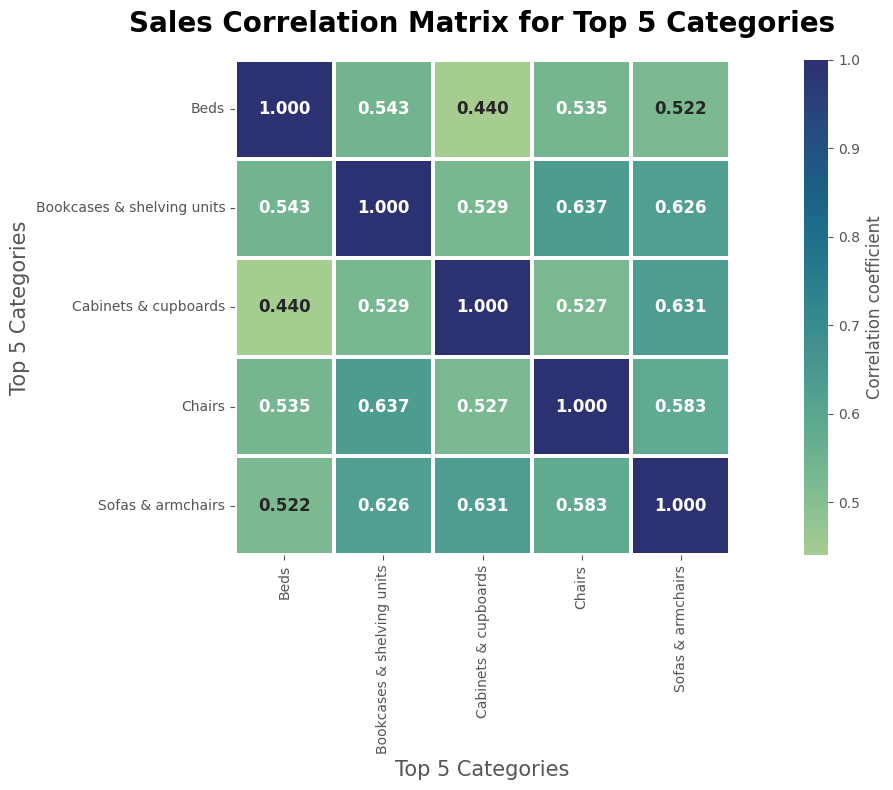

In [ ]:
plt.figure(figsize = (15, 8))

sns.heatmap(
    corr_matrix_by_spearman,
    annot = True,
    fmt = ".3f",
    cmap = "crest",
    linewidths = 1.5,
    square = True,
    annot_kws = {"size": 12, "weight": "bold"},
    cbar_kws = {"label": "Correlation coefficient"}
)

plt.title("Sales Correlation Matrix for Top 5 Categories", size = 20, fontweight =  "bold", pad = 20)
plt.xlabel("Top 5 Categories", size = 15)
plt.ylabel("Top 5 Categories", size = 15)
plt.style.use("ggplot")
plt.tight_layout()
plt.show()

На матриці кореляції, можемо побачити помірний прямий (монотонний) взаємозв'язок між всіма категоріями (коефіцієнт кореляції, знаходиться в діапазоні від `0.440` до `0.637`). Перевірка статистичної значущості показала, що для всіх пар категорій p_value < 0.05, що підтверджує те що, виявлені зв'язки є статистично значущими, а не випадковим збігом.

#7) Statistical analysis of differences between groups

### 7.1) Проаналізувати продажі за кожну дату зареєстрованих та незареєстрованих користувачів. Створити відповідні вибірки, проаналізувати розподіли даних в обох вибірках. Підібрати відповідний статистичний тест для порівняння вибірок. Зробити висновок щодо статистичної значущості отриманих результатів.


In [ ]:
df_sales.info()

<class 'pandas.core.frame.DataFrame'>
Index: 336076 entries, 0 to 349543
Data columns (total 20 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   date                 336076 non-null  datetime64[ns]
 1   session_id           336076 non-null  Int64         
 2   continent            336076 non-null  object        
 3   country              336076 non-null  object        
 4   device               336076 non-null  object        
 5   browser              336076 non-null  object        
 6   mobile_model_name    336076 non-null  object        
 7   operating_system     336076 non-null  object        
 8   language             336076 non-null  object        
 9   traffic_source_name  336076 non-null  object        
 10  channel              336076 non-null  object        
 11  account_id           27945 non-null   Int64         
 12  is_verified          27945 non-null   Int64         
 13  is_unsubscribed    

In [ ]:
df_sales["user_type"] = df_sales["account_id"].notna().map({True: "registered", False: "unregistered"})

pivot_corr_by_user_type = df_sales.pivot_table(values = "price", index = "date", columns = "user_type", aggfunc = "sum")
pivot_corr_by_user_type.head()

user_type,registered,unregistered
date,,
2020-11-01,21547.0,222745.5
2020-11-02,44956.8,310550.0
2020-11-03,29150.5,469829.1
2020-11-04,20982.2,318204.9
2020-11-05,25334.6,365942.0


In [ ]:
pivot_corr_by_user_type[::-1].head()

user_type,registered,unregistered
date,,
2021-01-27,14613.6,271727.1
2021-01-26,27213.6,344843.7
2021-01-25,34163.8,270925.5
2021-01-24,20914.0,222904.4
2021-01-23,16117.0,274488.5


In [ ]:
pivot_corr_by_user_type.isna().sum()

,0
user_type,
registered,0
unregistered,0


In [ ]:
pivot_corr_by_user_type.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 88 entries, 2020-11-01 to 2021-01-27
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   registered    88 non-null     float64
 1   unregistered  88 non-null     float64
dtypes: float64(2)
memory usage: 2.1 KB


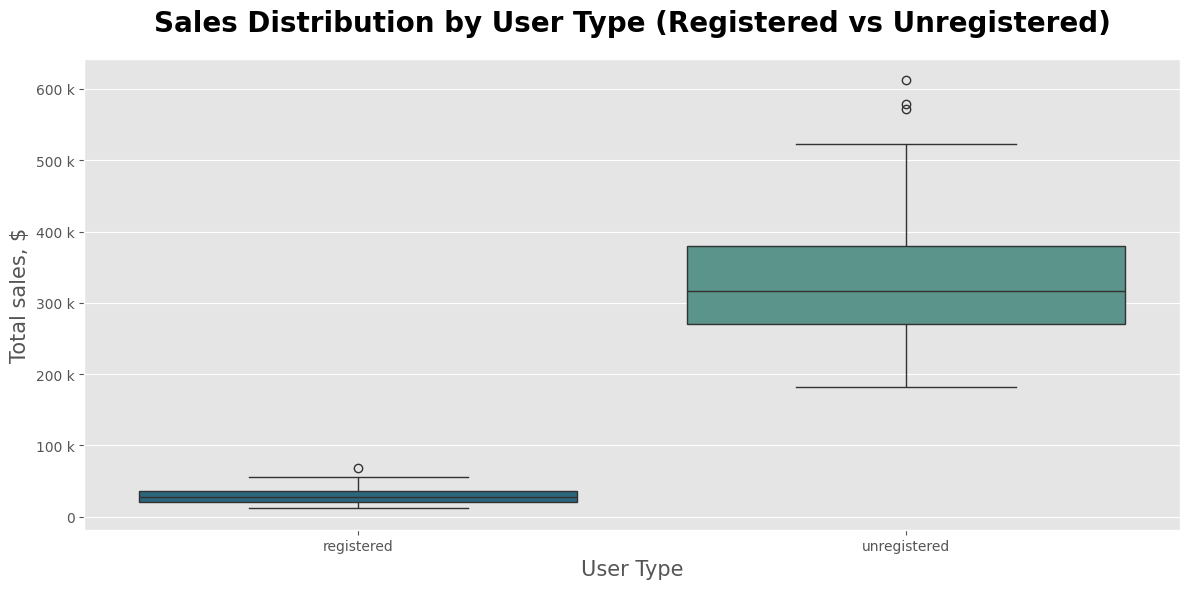

In [ ]:
plt.figure(figsize = (12, 6))
sns.boxplot(data = pivot_corr_by_user_type, palette = "crest_r")

plt.title("Sales Distribution by User Type (Registered vs Unregistered)", size = 20, fontweight = "bold", pad = 20)
plt.xlabel("User Type", size = 15)
plt.ylabel("Total sales, $", size = 15)
plt.gca().yaxis.set_major_formatter(ticker.EngFormatter())

plt.style.use("ggplot")
plt.tight_layout()
plt.show()

In [ ]:
pivot_corr_by_user_type.describe()

user_type,registered,unregistered
count,88.000000,88.000000
mean,29346.801136,333968.325000
std,10765.451652,92910.207068
min,11779.000000,182206.200000
25%,20717.375000,270485.500000
50%,28048.000000,316724.250000
75%,35774.700000,379948.475000
max,68151.100000,612358.400000


На даному відображенню boxplot (міжквартальний діапазон IQR), можемо бачити:
* **registered**
  * Медіана продажів - `$28 048`
  * Верхній викид - `$68 151.1`

* **unregistered**
  * Медіана продажів - `$316 724.25`
  * Декілька верхніх викидів - `$585 000`, `$590 000` і `$612 358.4`


In [ ]:
for user_type in pivot_corr_by_user_type.columns:
    _, p_val = scst.shapiro(pivot_corr_by_user_type[user_type])
    print(f"Category - {user_type}:\t")
    print(f"p_value = {p_val}")
    if (p_val < 0.05):
      print("\t The result is statistically significant, the data are not normally distributed")
    else:
      print("\t The data may be normally distributed")

Category - registered:	
p_value = 0.007295139880540744
	 The result is statistically significant, the data are not normally distributed
Category - unregistered:	
p_value = 0.0026183359245325936
	 The result is statistically significant, the data are not normally distributed


Перевірка нормальності розподілу за критерієм **Шапіро–Уілка** показала, що дані є не нормально розподілені для обох типів користувачів, тобто p_value < `0.05`. Також на графічного відображення (boxplot) ми бачимо, що в кожному типу користувача є викиди, мала вибірка даних (88 рядків), всі загальні продажі є зругпованими за датами, тому значення згруповані за однією датою, відповідає другому значення за така саму дату, тому вирішено обрати **Тест знаків Вілкоксона**



In [ ]:
registered_sales = pivot_corr_by_user_type["registered"]
unregistered_sales = pivot_corr_by_user_type["unregistered"]

u_stat, p_value = scst.wilcoxon(registered_sales, unregistered_sales)

print(f"U-statistic: {u_stat:.4f}")
print(f"p-value: {p_value:.4e}")

if p_value < 0.05:
    print("\nResult: The difference between the groups is statistically significant (p < 0.05). The null hypothesis is rejected")
else:
    print("\nResult: No statistically significant difference was found between the groups (p >= 0.05)")

U-statistic: 0.0000
p-value: 3.7320e-16

Result: The difference between the groups is statistically significant (p < 0.05). The null hypothesis is rejected


In [ ]:
pivot_corr_by_user_type.describe()

user_type,registered,unregistered
count,88.000000,88.000000
mean,29346.801136,333968.325000
std,10765.451652,92910.207068
min,11779.000000,182206.200000
25%,20717.375000,270485.500000
50%,28048.000000,316724.250000
75%,35774.700000,379948.475000
max,68151.100000,612358.400000


In [ ]:
df_sales["account_id"].nunique()

27945

Тобто після порівняння вибірок, можемо бачити, що різниця між продажами за кожну дату, зареєстрованих та незареєстрованих користувачів, є статистично значущою. Більшу частину доходу приносять саме не зареєстровані користувачі, для прикладу, їх середнє значення (`$333 968`) а для зареєстрованих (`$29 346`). Основний діапазон загальних продажів за день для незареєстрованих, тримається від `$270 485` до `$379 948`. А для зареєстрованих, від `$20 717` до `$35 774`. Зареєстрованих сесій, для зареєстрованих, лише `27 945` із `349 545` (8%), тому їхній денний дохід закономірно менший.

### 7.2) Проаналізувати кількість сесій за різними каналами трафіку. Підібрати відповідний тест. Визначити чи є статистично значущі відмінності між групами.


In [ ]:
df_copy.head()

,date,session_id,continent,country,device,browser,mobile_model_name,operating_system,language,traffic_source_name,channel,account_id,is_verified,is_unsubscribed,item_id,category,product_name,price,short_description
0,2021-01-19,7268004754,(not set),(not set),desktop,Chrome,Chrome,Web,en-gb,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
1,2021-01-06,8321293308,(not set),(not set),desktop,Chrome,Chrome,Web,Unknown,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
2,2020-11-05,4392362373,(not set),(not set),desktop,Chrome,Chrome,Web,Unknown,(organic),Organic Search,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
3,2020-12-09,140108698,(not set),(not set),desktop,Chrome,Safari,Web,en-us,(direct),Direct,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None
4,2020-11-10,8351127264,(not set),(not set),mobile,Safari,iPhone,Web,en-us,(organic),Organic Search,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None


In [ ]:
df_copy["channel"].unique()

array(['Direct', 'Organic Search', 'Paid Search', 'Undefined',
       'Social Search'], dtype=object)

In [ ]:
print(df_copy["session_id"].nunique())

349545


In [ ]:
total_sessions = len(df_copy)
undefined_sessions = (df_copy["channel"] == "Undefined").sum()

undefined_percentage = (undefined_sessions / total_sessions) * 100
print(f"Total count of sessions: {total_sessions}")
print(f"Count Undefined: {undefined_sessions}")
print(f"Percent Undefined: {undefined_percentage:.2f}%")

Total count of sessions: 349545
Count Undefined: 21483
Percent Undefined: 6.15%


In [ ]:
df_filter = df_copy[df_copy["channel"] != "Undefined"]

In [ ]:
pivot_corr_by_session_channel = df_filter.pivot_table(values = "session_id", index = "date", columns = "channel", aggfunc = "count")
pivot_corr_by_session_channel.head()

channel,Direct,Organic Search,Paid Search,Social Search
date,,,,
2020-11-01,608,920,706,214
2020-11-02,810,1242,970,315
2020-11-03,1216,1871,1367,392
2020-11-04,935,1425,1145,368
2020-11-05,845,1293,917,346


Так як умовою задачі було проаналізувати кількість сесій за різними каналами трафіку, тому було вирішено прибрати канал `Undefined` так як він є, значенням каналу, яке не можливо було визначити, тобто може бути що це один із відомих каналів, просто не визначений через помилку. Потрібно буде виправити це, щоб отримати повну картину аналізу.

In [ ]:
pivot_corr_by_session_channel.info()

<class 'pandas.core.frame.DataFrame'>
Index: 92 entries, 2020-11-01 to 2021-01-31
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Direct          92 non-null     Int64
 1   Organic Search  92 non-null     Int64
 2   Paid Search     92 non-null     Int64
 3   Social Search   92 non-null     Int64
dtypes: Int64(4)
memory usage: 4.0 KB


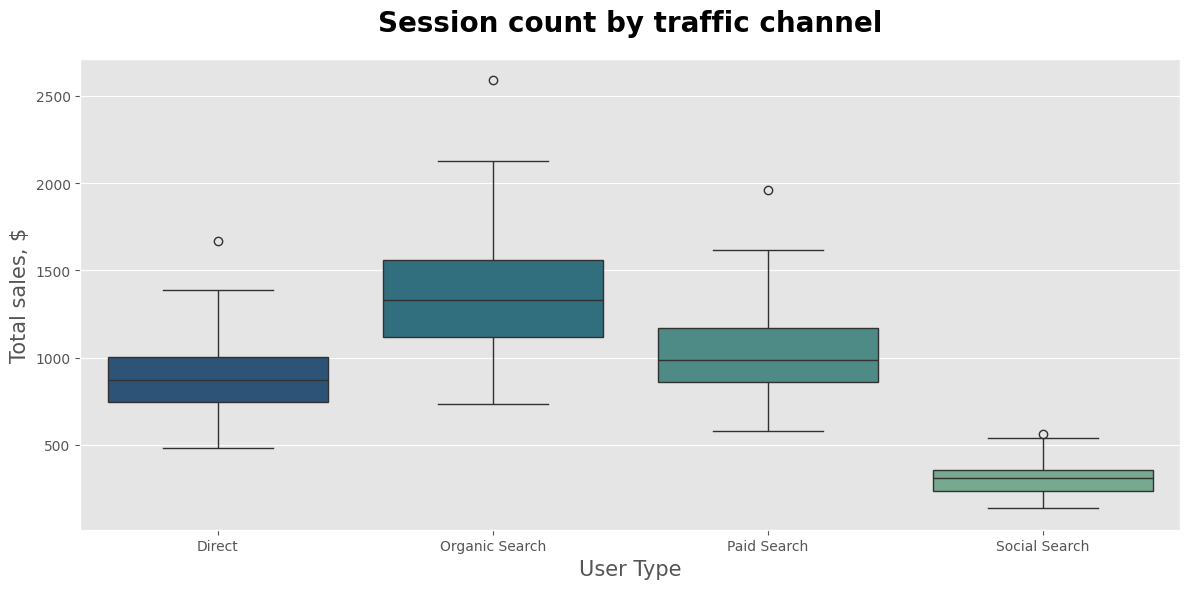

In [ ]:
plt.figure(figsize = (12, 6))
sns.boxplot(data = pivot_corr_by_session_channel, palette = "crest_r")

plt.title("Session count by traffic channel", size = 20, fontweight = "bold", pad = 20)
plt.xlabel("User Type", size = 15)
plt.ylabel("Total sales, $", size = 15)

plt.style.use("ggplot")
plt.tight_layout()
plt.show()

In [ ]:
pivot_corr_by_session_channel.describe()

channel,Direct,Organic Search,Paid Search,Social Search
count,92.0,92.0,92.0,92.0
mean,884.586957,1352.445652,1025.445652,303.413043
std,220.225267,336.572261,254.4211,88.127923
min,481.0,733.0,578.0,137.0
25%,744.0,1117.25,860.25,235.5
50%,869.5,1329.0,989.0,308.0
75%,1004.75,1558.75,1171.75,358.25
max,1668.0,2589.0,1959.0,561.0


На даному відображенню boxplot (міжквартальний діапазон IQR), можемо бачити:
* **Direct**
  * Медіана кількості сесій - `869.5`
  * Верхній викид - `1668`

* **Organic Search**
  * Медіана кількості сесій - `1329`
  * Верхній викид - `2589`

* **Paid Search**
  * Медіана кількості сесій - `989`
  * Верхній викид - `1959`

* **Social Search**
  * Медіана кількості сесій - `308`
  * Верхній викид - `560`



In [ ]:
for session_chanel in pivot_corr_by_session_channel.columns:
    _, p_val = scst.shapiro(pivot_corr_by_session_channel[session_chanel])
    print(f"Category - {session_chanel}:\t")
    print(f"p_value = {p_val}")
    if (p_val < 0.05):
      print("\t The result is statistically significant, the data are not normally distributed")
    else:
      print("\t The data may be normally distributed")

Category - Direct:	
p_value = 0.034278771626201326
	 The result is statistically significant, the data are not normally distributed
Category - Organic Search:	
p_value = 0.012271774671209374
	 The result is statistically significant, the data are not normally distributed
Category - Paid Search:	
p_value = 0.010833125972481636
	 The result is statistically significant, the data are not normally distributed
Category - Social Search:	
p_value = 0.14127184979117535
	 The data may be normally distributed


Перевірка нормальності розподілу за критерієм **Шапіро–Уілка** показала, що кількість сесій які мають канали, як: **Direct**, **Organic Search**, **Paid Search** дані є не нормально розподілені, тобто p_value < `0.05`. А для  **Social Search** можуть бути нормально розподілені, так як гіпотезу, про нормальність розподілу, відхилити не вдалося - p_value(`0.14`) > `0.05`. Також на графічного відображення (boxplot) ми бачимо, що в кожному типу користувача є викиди, мала вибірка даних (92 рядка), ми маємо декілька каналів, тобто 4 групи, всі сесії є зругпованими за датами, тому значення згруповані за однією датою, відповідає другому значення за така саму дату, тому вирішено обрати **Тест Фрідмана**, так як вибірки зв'язані.

In [ ]:
direct_сount_sessions = pivot_corr_by_session_channel["Direct"]
organic_сount_sessions = pivot_corr_by_session_channel["Organic Search"]
paid_сount_sessions = pivot_corr_by_session_channel["Paid Search"]
social_сount_sessions = pivot_corr_by_session_channel["Social Search"]

stat, p_value = scst.friedmanchisquare(direct_сount_sessions, organic_сount_sessions, paid_сount_sessions, social_сount_sessions)

print(f"Statistic: {stat:.4f}")
print(f"p-value: {p_value:.4e}")

if p_value < 0.05:
    print("\nResult: The difference between the groups is statistically significant (p < 0.05). The null hypothesis is rejected")
else:
    print("\nResult: No statistically significant difference was found between the groups (p >= 0.05)")

Statistic: 276.0000
p-value: 1.5535e-59

Result: The difference between the groups is statistically significant (p < 0.05). The null hypothesis is rejected


In [ ]:
pivot_corr_by_session_channel.describe()

channel,Direct,Organic Search,Paid Search,Social Search
count,92.0,92.0,92.0,92.0
mean,884.586957,1352.445652,1025.445652,303.413043
std,220.225267,336.572261,254.4211,88.127923
min,481.0,733.0,578.0,137.0
25%,744.0,1117.25,860.25,235.5
50%,869.5,1329.0,989.0,308.0
75%,1004.75,1558.75,1171.75,358.25
max,1668.0,2589.0,1959.0,561.0


Тобто після порівняння вибірок, можемо бачити, що різниця між сесіями за каналами, є статистично значущою. Каналом з найбільшою кількістю сесій, є **Organic Search**, основний діапазон кількості сесій за день для цього каналу, тримається від `1117` до `1558`. А для каналу з найменшою кількістю сесій (**Social Search**), від `235` до `358`. Також потрібно спробувати виправити категорію невідомі канали, щоб побачити повну картину.

### 7.3) Визначити чи відрізняється статистично доля сесій з органічним трафіком у Європі та Америці. Підібрати відповідний тест. Провести потрібні обчислення для створення вхідних даних до тесту.


In [ ]:
df_copy.head()

,date,session_id,continent,country,device,browser,mobile_model_name,operating_system,language,traffic_source_name,...,account_id,is_verified,is_unsubscribed,item_id,category,product_name,price,short_description,day_of_week,user_type
0,2021-01-19,7268004754,(not set),(not set),desktop,Chrome,Chrome,Web,en-gb,(direct),...,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None,Tuesday,unregistered
1,2021-01-06,8321293308,(not set),(not set),desktop,Chrome,Chrome,Web,Unknown,(direct),...,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None,Wednesday,unregistered
2,2020-11-05,4392362373,(not set),(not set),desktop,Chrome,Chrome,Web,Unknown,(organic),...,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None,Thursday,unregistered
3,2020-12-09,140108698,(not set),(not set),desktop,Chrome,Safari,Web,en-us,(direct),...,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None,Wednesday,unregistered
4,2020-11-10,8351127264,(not set),(not set),mobile,Safari,iPhone,Web,en-us,(organic),...,<NA>,<NA>,<NA>,<NA>,None,None,NaN,None,Tuesday,unregistered


In [ ]:
continents = ["Europe", "Americas"]
df_filter_continent = df_copy[df_copy["continent"].isin(continents)]

In [ ]:
total_group_by_continet_and_channel = df_filter_continent.groupby("continent").agg(total_sessions = ("session_id", "count"), organic_sessions = ("channel", lambda x: (x == "Organic Search").sum()))
total_group_by_continet_and_channel

,total_sessions,organic_sessions
continent,,
Americas,193179,68671
Europe,65135,23195


In [ ]:
import statsmodels.api as sm

In [ ]:
z_stat, p_value = sm.stats.proportions_ztest(
    total_group_by_continet_and_channel["organic_sessions"],
    total_group_by_continet_and_channel["total_sessions"],
)

print(f"Z-statistic: {z_stat}")
print(f"P-value: {p_value}")

if p_value < 0.05:
    print("There is a statistically significant difference between organic search in Americas and Europe")
else:
    print("No statistically significant difference between organic search in Americas and Europe")

Z-statistic: -0.28951412926103953
P-value: 0.7721879690501752
No statistically significant difference between organic search in Americas and Europe


З результат ми бачимо, що p_value(0.77) > 0.05 і це означає що ми не можемо відкинути нульову гіпотезу, про те, що між долею сесій органічного трафіку на Американському та Євпропейському континтах немає різниці. Також це помітно з того що:
* **Americas** - має загальну кількість сесій `193 179` а з **Organic Search** `68 671`. Їх відношення дорівнює майже `3`, тобто `193 179 / 68 671`
* **Europe** - має загальну кількість сесій `65 135` а з **Organic Search** `23 195`. Їх відношення дорівнює майже `3`, тобто `65 135 / 23 195`

#8) Report

Даний датасет містить `349 545` унікальних сесій.

Загальну суму продажів `$31 971 731.1`.

Зареєстровані користувачі - `27 945`.

Кількість замовлень - `33 538`.

Містить такий часовий період: `від 2020-11-01 по 2021-01-31`.

# **1) Geography and Top Categories**


`Топ країн та континентів, по загальним продажам та кількістю замовлень:`

***Континети:***

1. Americas
2. Asia
3. Europe

***Країни:***

1. United States
2. India
3. Canada
4. United Kingdom
5. France

`Топ 10 категорій товарів за загальною сумою:`
| Позиції 1–5 | Позиції 6–10 |
| :--- | :--- |
| 1. Sofas & armchairs | 6. Outdoor furniture |
| 2. Chairs | 7. Tables & desks |
| 3. Beds | 8. Chests of drawers & drawer units |
| 4. Bookcases & shelving units | 9. Bar furniture |
| 5. Cabinets & cupboards | 10. Children's furniture |


`% від загальних продаж у розрізі типів та моделей девайсів:`

| Device | Percent from Total |
| :--- | :--- |
| 1. desktop | 59%  |
| 2. mobile | 38.73% |
| 3. tablet | 2.26% |

# **2) Analysis of Traffic Channels and User Behavior**

`% від загальних продаж у розрізі джерел трафіку:`

| traffic source name | Percent from Total |
| :--- | :--- |
| 1. organic | 34.20%  |
| 2. direct | 23.44% |
| 3. Other | 18.45% |
| 4. referral | 17.65% |
| 5. data deleted | 6.26% |


`Різниця кількості покупок між зареєстрованими користувачами з розсилкою та без:`

Майже ***80%*** від усієї кількості покупок, зареєстрованих користувачів, роблять ті хто досі підписані на розсилки, решту роблять ті хто відписався від розсилки

`Топ 5 країн по зареєстрованим користувачам:`

1. United States
2. India
3. Canada
4. United Kingdom
5. France

# **3) Trends and Seasonality**

Основний діапазон загальних сум продажу, знаходиться від 200 k до 500 k. Майже всі дні знаходяться в цьому діапазоні. Маємо в основному поступовий хвилястий ріст(до `$624 104`), з негативним трендом (до `$210 000`), який відбуваєть з середину грудня до початку січня 2021. Робити висновки, щодо сезоності, не є можливим так як діапазону дат не достатньо для цього.

# **4) Results of the statistical analysis**

* **Кореляційний аналіз:**

Виявлено сильний прямий зв'язок між кількістю сесій і загальними продажами (коефіцієнт Спірмена 0.90, p < 0.05).

Помірні та сильні кореляції (коефіцієнти від 0.38 до 0.76, p_value < 0.05) також підтверджено між топ-континентами, каналами трафіку та товарними категоріями.

* **Порівняння груп користувачів:**

Зафіксовано статистично значущу різницю в продажах між зареєстрованими та незареєстрованими покупцями. Основний дохід генерують незареєстровані користувачі (середнє значення `$319 450` і `$28 070` у зареєстрованих). Але потрібно розуміти, що кількість сесій з зареєстрованими клієнтами, лише **8%** (27 945 із 349 545).

Конверсія в замовленнях, для зареєстрованих користувачів, близько **9.9%** (2 781 замовлення на 27 945 сесій). У незареєстрованих вона близько **9.6%** (30 757 на 321 600 сесій). Середній чек приблизно `$929` і `$956`. Тому така різниця в значеннях продаж, через кількість користувачів в обох групах.

* **Канали трафіку:**

Існують статистично значущі відмінності за кількістю сесій між каналами. Лідером є ***Organic Search*** (1117 – 1558 сесій щодня), тоді як найнижчі показники зафіксовано у ***Social Search*** (235 – 358 сесій щодня).

* **Регіональне порівняння:**

Частка органічного трафіку в Європі та Америці є практично ідентичною (співвідношення загальних сесій до органічних становить близько 3 для обох регіонів). Нульову гіпотезу відхилити не можна (p_value = 0.77 > 0.05), тобто статистично значущих відмінностей між регіонами за цією метрикою немає.

# **5) Conclusion**

1. Направити додаткові зусилля на масштабування найефективніших джерел трафіку (Organic та Direct). Вони приносять майже 58% від загального доходу.
2. Намагатись збільшити кількість зареєстрованих користувачів (персоналізовані знижки для зареєстрованих акаунтів, спеціальні пропозиції в розсилках)
3. Продовжувати основний розвиток для користувачів з типами девайсів, як: Desktop(59%), Mobile(38,7%) від загального доходу.
4. Зосередити основні маркетингові зусилля на **United States** та континенті **Americas**. Продовжувати розвивати зусилля для країн, які входять в топ 5 по доходам(United States, India, Canada, United Kingdom, France).
5. Продвигати рекламні компанії для категорій яку приносять основний дохід(Sofas & armchairs, Chairs, Beds).

In [ ]:
df_copy.to_csv("dashboard_portfolio_data.csv", index = False)

https://public.tableau.com/views/onlinestoresalesanalytics/Overview?:language=en-US&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link